# 1113 — Unified QCRB engine (replaces the duplicated code in 1104 and 1109)

Protocol (derivation draft, Sec. V.A, eq. 141–150): prepare `S(r)|n>`, drive the signal `D(β)` while dephasing / cooling / heating act, split with the SDF `D(±iα)`, trace out the motion, and take QCRB = 1/QFI of the qubit.

All noise strengths are dimensionless: `Γφt`, `Γct`, `Γht` = rate × exposure time `t_sig`.

What is different from 1104 / 1109:

- **One engine for both notebooks.** The α-sweep plot (1104) and the phase diagram (1109) call the same functions.
- **Exact noise step.** The dissipators never mix different diagonals of ρ, so each time slice applies the exact dephasing + cooling + heating map instead of first-order Kraus operators. Combined with a symmetric (Strang) split against the drive, about `6·Γt` steps are enough, where the old code needed `200·Γt`.
- **Real arithmetic.** For a real drive the motional ρ stays real and symmetric, so all matrices are `Float64`.
- **Exact β-derivative.** `∂ρ/∂β` is propagated alongside ρ, so there is no second "perturbed" run and no finite-difference step.
- **Readout by eq. 149–150.** `C = Tr[D(2iα)ρ]` and the closed-form qubit QFI replace the tensor product, partial trace and eigen-decomposition.
- **No readout-frame shift.** A β-independent shift only multiplies `C` by a constant phase, so it is dropped. (1104's last cell shifted the perturbed state by its own mean, which removed the signal; see the notes at the end.)

In [1]:
ENV["MPLBACKEND"] = "agg"
using LinearAlgebra, Printf
using PyPlot

BLAS.set_num_threads(1)   # 51×51 products are faster single-threaded; parallelism is over sweep points
println("Julia threads: ", Threads.nthreads())

Julia threads: 1


## 1. Closed forms from the derivation

`qcrb_theory` is eq. 33 (no noise), eq. 74 (cooling) and eq. 106 (thermal bath) in one function, written for separate cooling and heating rates: net damping `K = Γct − Γht`, diffusion `(Γct + Γht)(1 − e^{−K})/K`.

In [2]:
function laguerre(n::Int, x::Real)
    n == 0 && return 1.0
    Lm, L = 1.0, 1.0 - x
    for k in 1:(n-1)
        Lm, L = L, ((2k + 1 - x) * L - k * Lm) / (k + 1)
    end
    return L
end

# eq. 33 / 74 / 106. Gc, Gh are Γ_c·t_sig and Γ_h·t_sig. Valid for pure heating too (K < 0).
function qcrb_theory(α::Real, n::Int; r::Real=0.0, Gc::Real=0.0, Gh::Real=0.0)
    K = Gc - Gh
    decay = exp(-K)
    diffusion = abs(K) < 1e-9 ? (Gc + Gh) : (Gc + Gh) * (1 - decay) / K     # (2n̄+1)(1 − e^{−Γt})
    f = abs(K) < 1e-9 ? 1.0 - K / 4 : (2 / K) * (1 - exp(-K / 2))           # laser-drift factor, eq. 71
    B = diffusion + decay * exp(-2r)                                        # B_var, eq. 107
    L = laguerre(n, 4α^2 * decay * exp(-2r))
    return exp(4α^2 * B) / (16α^2 * f^2 * L^2)
end

min_qcrb_theory(n; r=0.0, Gc=0.0, Gh=0.0, αs=0.01:0.002:6.0) =
    minimum(qcrb_theory(a, n; r=r, Gc=Gc, Gh=Gh) for a in αs)

# eq. 103 / 117: first-order crossover of states nA and nB, as dimensionless Γ·t_sig
function crossover_first_order(nA::Int, nB::Int; r::Real=0.0, nbar::Real=0.0)
    ys = 0.001:0.001:40.0
    q0(n, y) = exp(y) / (4y * laguerre(n, y)^2)                             # eq. 77 with r = 0
    yA = ys[argmin([q0(nA, y) for y in ys])]; yB = ys[argmin([q0(nB, y) for y in ys])]
    return (log(q0(nB, yB)) - log(q0(nA, yA))) / ((2nbar + 1) * exp(2r) * (yA - yB))
end

# eq. 126 and eq. 139 (dephasing models from the draft; compared with the exact numerics below)
function beta_eff(β::Real, Gphi::Real)
    Gphi < 1e-5 && return β / sqrt(3)
    x = Gphi / 2
    return sqrt(max(0.0, (β^2 / x^2) * (1 + (2 / x) * (exp(-x) - 1) - (1 / (2x)) * (exp(-2x) - 1))))
end
dephasing_K(n::Int) = minimum(1 / (64a^2 * (exp(-2a^2) * laguerre(n, 4a^2))^2) for a in 0.01:0.001:4.0)

println("first-order crossovers Γt (n=1/0, 2/1, 3/2): ", [round(crossover_first_order(n, n - 1), digits=4) for n in 1:3])

first-order crossovers Γt (n=1/0, 2/1, 3/2): [0.2178, 0.071, 0.0409]


## 2. Engine

Cost per sweep point: `steps × (4 real 51×51 products + one O(N³/3) noise update)`, and memory is a handful of 51×51 `Float64` buffers. With dephasing only, the noise update is a single element-wise mask.

In [3]:
const DIM = 51                      # Fock levels 0..50, same cutoff as 1104 / 1109

# exp of the generator in a padded basis, cropped to d×d (removes truncation error on the populated block)
function displace_matrix(ξ::Number, d::Int=DIM; pad::Int=2d)
    a = diagm(1 => sqrt.(1:(pad-1)))
    return exp(ξ * a' - conj(ξ) * a)[1:d, 1:d]
end

# S(r)|n> with the QuantumOptics.squeeze(b, r) sign convention (improves sensitivity for r > 0)
function squeezed_fock(n::Int, r::Real, d::Int=DIM; pad::Int=2d)
    v = zeros(pad); v[n+1] = 1.0
    if r != 0
        a = diagm(1 => sqrt.(1:(pad-1)))
        v = exp((r / 2) * (a^2 - (a')^2)) * v
    end
    v = v[1:d]
    return v ./ norm(v)
end

# Exact map of dephasing + cooling + heating over a fraction `frac` of the exposure.
# Element ρ[m, m+k] only couples to ρ[m±1, m±1+k], so there is one small real matrix per diagonal k.
struct NoiseStep
    E::Vector{Matrix{Float64}}      # E[k+1] acts on the k-th superdiagonal
    diagonal_only::Bool             # pure dephasing: only the mask is needed
    mask::Matrix{Float64}
end

function NoiseStep(Gphi::Real, Gc::Real, Gh::Real, frac::Real, d::Int)
    N = d - 1
    mask = [exp(-0.5 * Gphi * frac * (i - j)^2) for i in 1:d, j in 1:d]            # eq. 124 / 145
    (Gc == 0 && Gh == 0) && return NoiseStep(Matrix{Float64}[], true, mask)
    up(j) = j < N ? j + 1.0 : 0.0                 # <j|a a†|j> with a† cut at N, so the trace is conserved
    E = Vector{Matrix{Float64}}(undef, d)
    for k in 0:N
        len = N - k + 1
        T = zeros(len, len)
        for i in 1:len
            m = i - 1
            T[i, i] = -0.5 * Gc * (2m + k) - 0.5 * Gh * (up(m) + up(m + k)) - 0.5 * Gphi * k^2
            i < len && (T[i, i+1] = Gc * sqrt((m + 1) * (m + k + 1)))               # cooling, eq. 142
            i > 1 && (T[i, i-1] = Gh * sqrt(m * (m + k)))                           # heating, eq. 143
        end
        E[k+1] = exp(T .* frac)
    end
    return NoiseStep(E, false, mask)
end

function apply_noise!(ρ::Matrix{Float64}, ns::NoiseStep, buf::Vector{Float64})
    if ns.diagonal_only
        ρ .*= ns.mask
        return ρ
    end
    d = size(ρ, 1)
    @inbounds for k in 0:(d-1)
        len = d - k
        Ek = ns.E[k+1]
        for i in 1:len
            s = 0.0
            for j in 1:len
                s += Ek[i, j] * ρ[j, j+k]
            end
            buf[i] = s
        end
        for i in 1:len
            ρ[i, i+k] = buf[i]; ρ[i+k, i] = buf[i]
        end
    end
    return ρ
end

default_steps(Gphi, Gc, Gh) = max(64, ceil(Int, 6 * max(Gphi, Gc, Gh)))

# Everything that depends on the noise point but not on the initial state: build once, reuse for every (n, r).
struct Drive
    D::Matrix{Float64}; Dt::Matrix{Float64}; G::Matrix{Float64}
    full::NoiseStep; half::NoiseStep; steps::Int
end

function Drive(β::Real, Gphi::Real, Gc::Real, Gh::Real; steps::Int=default_steps(Gphi, Gc, Gh), d::Int=DIM)
    a = diagm(1 => sqrt.(1:(d-1)))
    G = a' - a                                    # D(β) = exp(βG) is a real rotation for real β
    D = exp((β / steps) .* G)
    return Drive(D, Matrix(D'), G, NoiseStep(Gphi, Gc, Gh, 1 / steps, d), NoiseStep(Gphi, Gc, Gh, 0.5 / steps, d), steps)
end

# ρ(β) and ∂ρ/∂β after the noisy drive (eq. 141). Strang split: noise(½)·[drive·noise]^(S−1)·drive·noise(½).
function propagate(ψ0::Vector{Float64}, drv::Drive)
    d = length(ψ0); S = drv.steps
    ρ = ψ0 * ψ0'; dρ = zeros(d, d)
    t1 = similar(ρ); t2 = similar(ρ); buf = zeros(d)
    apply_noise!(ρ, drv.half, buf)
    for s in 1:S
        mul!(t1, drv.D, ρ);  mul!(ρ, t1, drv.Dt)                 # ρ  ← D ρ D'
        mul!(t1, drv.D, dρ); mul!(dρ, t1, drv.Dt)                # dρ ← D dρ D' + [G, ρ]/S
        mul!(t1, drv.G, ρ);  mul!(t2, ρ, drv.G)
        @. dρ += (t1 - t2) / S
        ns = s == S ? drv.half : drv.full
        apply_noise!(ρ, ns, buf); apply_noise!(dρ, ns, buf)
    end
    return ρ, dρ
end

# eq. 149–150: C = Tr[D(2iα)ρ],  QFI = |∂C|² + Re(C*∂C)² / (1 − |C|²)
function qcrb_from_state(ρ::Matrix{Float64}, dρ::Matrix{Float64}, V::Matrix{ComplexF64})
    C = zero(ComplexF64); dC = zero(ComplexF64)
    @inbounds for j in axes(V, 2), i in axes(V, 1)
        C += V[j, i] * ρ[i, j]; dC += V[j, i] * dρ[i, j]
    end
    qfi = abs2(dC) + real(conj(C) * dC)^2 / max(1 - abs2(C), 1e-300)
    return qfi > 0 ? 1 / qfi : Inf
end

readout_matrices(αs; d::Int=DIM) = [displace_matrix(2im * a, d) for a in αs]

# QCRB(α) curve for one state and one noise point. `tail` is the population in the top 5 Fock levels:
# if it is not ≈ 0 the cutoff DIM is too small for that point (this happens for strong heating).
function qcrb_curve(n::Int, αs, Vs; r=0.0, β=2.0, Gphi=0.0, Gc=0.0, Gh=0.0, steps=default_steps(Gphi, Gc, Gh))
    ρ, dρ = propagate(squeezed_fock(n, r), Drive(β, Gphi, Gc, Gh; steps=steps))
    return [qcrb_from_state(ρ, dρ, V) for V in Vs], sum(@view ρ[diagind(ρ)[end-4:end]])
end

qcrb_curve (generic function with 1 method)

## 3. Checks against the derivation

Cooling, heating and squeezing have closed forms (eq. 33 / 74 / 106), so the engine can be compared directly. Dephasing has none, so it is checked by doubling the step count.

In [4]:
αs_check = collect(0.05:0.01:2.6)
Vs_check = readout_matrices(αs_check)

println("engine vs closed form (β = 2)")
println("  n    r    Γct   Γht  steps   min QCRB engine   min QCRB theory   rel.diff   α_opt")
for (n, r, Gc, Gh) in ((0, 0.0, 0.0, 0.0), (1, 0.0, 0.0, 0.0), (3, 0.0, 0.0, 0.0), (1, 0.4, 0.0, 0.0), (2, 0.4, 0.3, 0.0),
                       (1, 0.0, 1.0, 0.0), (3, 0.0, 10.0, 0.0), (3, 0.0, 100.0, 0.0), (1, 0.0, 0.5, 0.2), (2, 0.2, 0.0, 0.3))
    q, _ = qcrb_curve(n, αs_check, Vs_check; r=r, Gc=Gc, Gh=Gh)
    th = minimum(qcrb_theory(a, n; r=r, Gc=Gc, Gh=Gh) for a in αs_check)
    @printf("  %d  %.1f  %5.1f  %4.1f  %5d   %15.6g   %15.6g   %8.1e   %.2f\n", n, r, Gc, Gh, default_steps(0, Gc, Gh),
            minimum(q), th, abs(minimum(q) - th) / th, αs_check[argmin(q)])
end

println("\ndephasing: default step count vs 16× more steps (β = 2)")
println("  n   Γφt  steps   min QCRB    rel.change")
for (n, G) in ((1, 0.1), (1, 1.0), (3, 1.0), (1, 10.0), (3, 100.0))
    S = default_steps(G, 0, 0)
    q1 = minimum(qcrb_curve(n, αs_check, Vs_check; Gphi=G)[1])
    q2 = minimum(qcrb_curve(n, αs_check, Vs_check; Gphi=G, steps=16S)[1])
    @printf("  %d  %5.1f  %5d   %9.6g   %8.1e\n", n, G, S, q1, abs(q1 - q2) / q2)
end

engine vs closed form (β = 2)
  n    r    Γct   Γht  steps   min QCRB engine   min QCRB theory   rel.diff   α_opt
  0  0.0    0.0   0.0     64           0.67957           0.67957    2.4e-14   0.50
  1  0.0    0.0   0.0     64          0.374884          0.374884    1.8e-14   0.97
  3  0.0    0.0   0.0     64          0.256426          0.256426    3.3e-14   1.63
  1  0.4    0.0   0.0     64          0.168419          0.168419    3.2e-12   1.44
  2  0.4    0.3   0.0     64           1.21108           1.21108    4.6e-07   1.06
  1  0.0    1.0   0.0     64           1.99675           1.99674    5.1e-06   0.36
  3  0.0   10.0   0.0     64            17.234           17.2252    5.1e-04   0.50
  3  0.0  100.0   0.0    600           1699.91           1698.93    5.8e-04   0.50
  1  0.0    0.5   0.2     64           2.39218           2.39218    4.6e-07   0.28
  2  0.2    0.0   0.3     64           1.31714           1.31714    4.6e-07   0.67

dephasing: default step count vs 16× more steps (β = 2)

### Independent check: QuantumOptics master-equation ODE

Same physics as 1104's `master_dynamic` simulation, in dimensionless time (`t ∈ [0, 1]`, drive rate β, jump rates `Γt`). This is the only cell that needs QuantumOptics.

In [5]:
using QuantumOptics

function qcrb_curve_ode(n::Int, αs, Vs; β=2.0, Gphi=0.0, Gc=0.0, Gh=0.0, dβ=1e-3)
    b = FockBasis(DIM - 1)
    a = destroy(b); at = create(b); nop = number(b)
    J = typeof(dense(a))[]; rates = Float64[]
    Gphi > 0 && (push!(J, dense(nop)); push!(rates, Gphi))
    Gc > 0 && (push!(J, dense(a)); push!(rates, Gc))
    Gh > 0 && (push!(J, dense(at)); push!(rates, Gh))
    final(βv) = begin
        H = dense(1im * βv * (at - a))
        _, ρt = timeevolution.master([0.0, 1.0], dm(fockstate(b, n)), H, J; rates=rates, reltol=1e-10, abstol=1e-12)
        ρt[end].data
    end
    ρ = final(β); dρ = (final(β + dβ) - final(β - dβ)) / (2dβ)
    out = Float64[]
    for V in Vs
        C = tr(V * ρ); dC = tr(V * dρ)
        push!(out, 1 / (abs2(dC) + real(conj(C) * dC)^2 / (1 - abs2(C))))
    end
    return out
end

println("engine vs QuantumOptics ODE (n = 1, β = 2)")
println("   Γφt   Γct   Γht   min QCRB engine   min QCRB ODE   max rel.diff over α   t_engine   t_ODE")
for (Gp, Gc, Gh) in ((1.0, 0.0, 0.0), (3.0, 0.0, 0.0), (0.0, 0.5, 0.0), (1.0, 0.3, 0.1))
    qcrb_curve(1, αs_check, Vs_check; Gphi=Gp, Gc=Gc, Gh=Gh)
    te = @elapsed qe = qcrb_curve(1, αs_check, Vs_check; Gphi=Gp, Gc=Gc, Gh=Gh)[1]
    to = @elapsed qo = qcrb_curve_ode(1, αs_check, Vs_check; Gphi=Gp, Gc=Gc, Gh=Gh)
    keep = qo .< 1e3
    @printf("  %4.1f  %4.1f  %4.1f   %15.6g   %12.6g   %19.1e   %6.3f s   %5.1f s\n", Gp, Gc, Gh, minimum(qe), minimum(qo),
            maximum(abs.(qe .- qo)[keep] ./ qo[keep]), te, to)
end

engine vs QuantumOptics ODE (n = 1, β = 2)
   Γφt   Γct   Γht   min QCRB engine   min QCRB ODE   max rel.diff over α   t_engine   t_ODE
   1.0   0.0   0.0           1.34845        1.34828               3.7e-04    0.004 s     5.7 s
   3.0   0.0   0.0           5.42664        5.42345               1.8e-03    0.004 s     1.8 s
   0.0   0.5   0.0           2.07488        2.07488               1.4e-05    0.013 s     0.4 s
   1.0   0.3   0.1           3.98036         3.9803               2.8e-04    0.012 s     1.1 s


## 4. QCRB versus readout displacement α (the 1104 plot)

Inputs are dimensionless. To convert 1104's rates in Hz, multiply by `t_sig`; the optional cell below gets `t_sig` from the laser parameters with IonSim.

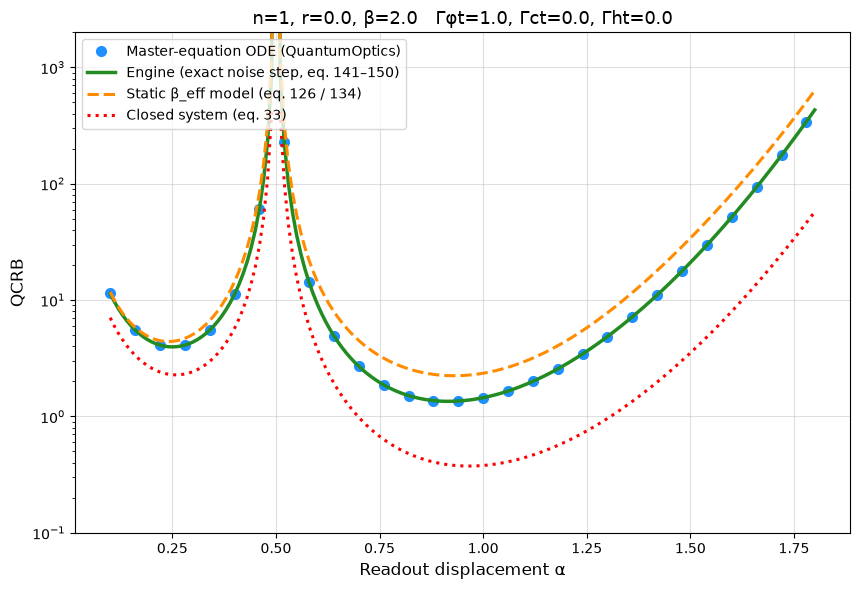

min QCRB = 1.3484 at α = 0.92


In [6]:
function plot_qcrb_vs_alpha(n::Int=1; r=0.0, β=2.0, Gphi=0.0, Gc=0.0, Gh=0.0, αs=collect(0.1:0.01:1.8), ode::Bool=true)
    Vs = readout_matrices(αs)
    q, tail = qcrb_curve(n, αs, Vs; r=r, β=β, Gphi=Gphi, Gc=Gc, Gh=Gh)
    tail > 1e-6 && println("warning: $(round(tail, sigdigits=2)) of the population is at the Fock cutoff; raise DIM")

    fig = figure(figsize=(10, 6.5))
    if ode && r == 0
        idx = 1:6:length(αs)
        plot(αs[idx], qcrb_curve_ode(n, αs[idx], Vs[idx]; β=β, Gphi=Gphi, Gc=Gc, Gh=Gh), "o", markersize=7,
             color="dodgerblue", label="Master-equation ODE (QuantumOptics)")
    end
    plot(αs, q, "-", color="forestgreen", linewidth=2.5, label="Engine (exact noise step, eq. 141–150)")
    if Gphi == 0
        plot(αs, [qcrb_theory(a, n; r=r, Gc=Gc, Gh=Gh) for a in αs], "--", color="black", linewidth=1.8, label="Closed form (eq. 74 / 106)")
    elseif Gc == 0 && Gh == 0 && r == 0
        be = beta_eff(β, Gphi); f = (2 / Gphi) * (1 - exp(-Gphi / 2))
        ψ = displace_matrix(be)[:, n+1]
        ρs = (ψ * ψ') .* [exp(-0.5 * Gphi * (i - j)^2) for i in 1:DIM, j in 1:DIM]
        Dm = displace_matrix(-be); ρs = Dm * ρs * Dm'
        plot(αs, [1 / (16a^2 * f^2 * abs2(tr(V * ρs))) for (a, V) in zip(αs, Vs)], "--", color="darkorange", linewidth=2.2,
             label="Static β_eff model (eq. 126 / 134)")
    end
    plot(αs, [qcrb_theory(a, n; r=r) for a in αs], ":", color="red", linewidth=2.2, label="Closed system (eq. 33)")

    yscale("log"); ylim(1e-1, 2e3)
    xlabel("Readout displacement α", fontsize=12); ylabel("QCRB", fontsize=12)
    title("n=$n, r=$r, β=$β   Γφt=$Gphi, Γct=$Gc, Γht=$Gh", fontsize=13)
    legend(fontsize=10, loc="upper left"); grid(alpha=0.4)
    display(fig); close(fig)
    @printf("min QCRB = %.5g at α = %.2f\n", minimum(q), αs[argmin(q)])
    return nothing
end

plot_qcrb_vs_alpha(1; Gphi=1.0)                      # pure dephasing: exact vs the static β_eff model

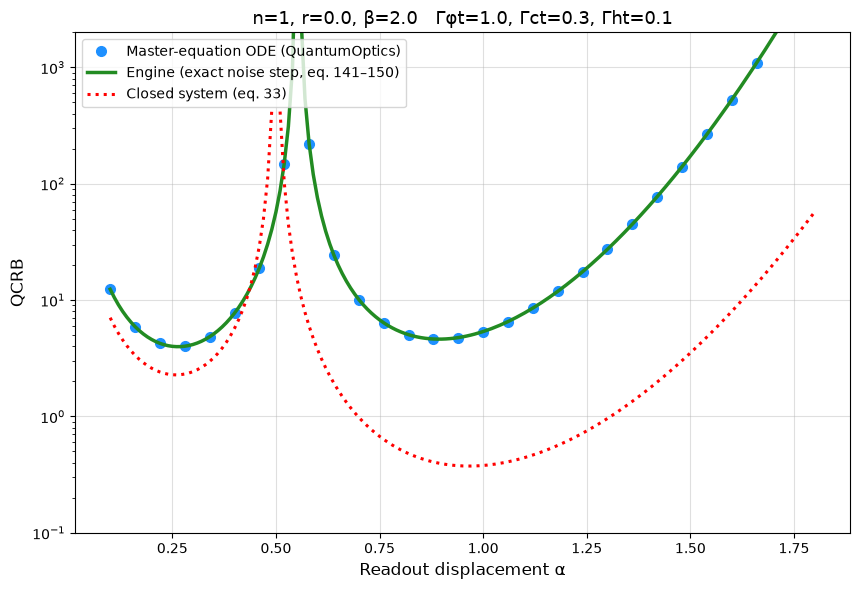

min QCRB = 3.9804 at α = 0.26


In [7]:
plot_qcrb_vs_alpha(1; Gphi=1.0, Gc=0.3, Gh=0.1)      # all three channels at once

In [8]:
# Optional: t_sig from the laser parameters used in 1104 (needs IonSim). Γt = rate[Hz] × t_sig.
try
    @eval using IonSim
    function tsig_seconds(laser_intensity::Float64, β::Float64; trap_freq=19e5)
        hbar = 1.0545718e-34; amu = 1.66053906e-27; m = 39.96259 * amu
        ion = Ca40([("S1/2", -1/2, "g"), ("D5/2", -5/2, "e")])
        chain = LinearChain(ions=[ion], comfrequencies=(x=3e6, y=3e6, z=trap_freq), selectedmodes=(; z=[1]))
        chamber = Chamber(iontrap=chain, B=1e-13, Bhat=ẑ)
        λ = transitionwavelength(ion, ("g", "e"), chamber)
        η = ((2π / λ) / sqrt(2)) * sqrt(hbar / (2 * m * 2π * trap_freq))
        laser = Laser(I=laser_intensity, k=(x̂ + ẑ) / √2, ϵ=ŷ, λ=λ)
        Ω = IonSim.matrixelement(ion, ("g", "e"), laser_intensity, polarization(laser), wavevector(laser), (; x=0.0, y=0.0, z=1.0)) * 2π
        return 2β / (η * Ω)
    end
    t = Base.invokelatest(tsig_seconds, 1e3, 2.0)
    @printf("t_sig(I = 1e3, β = 2) = %.4g s  →  365 Hz dephasing: Γφt = %.3f;  50 Hz cooling: Γct = %.3f;  10 Hz heating: Γht = %.4f\n",
            t, 365t, 50t, 10t)
catch err
    println("IonSim not available, skipping the Hz → Γt conversion: ", sprint(showerror, err)[1:min(end, 200)])
end

t_sig(I = 1e3, β = 2) = 0.004413 s  →  365 Hz dephasing: Γφt = 1.611;  50 Hz cooling: Γct = 0.221;  10 Hz heating: Γht = 0.0441


## 5. Phase diagram: best QCRB over α versus noise (the 1109 plot)

Black dotted curves are the closed form (shown when there is no dephasing). Grey ticks on the bottom axis are the first-order crossovers of eq. 103. Points where the Fock cutoff is hit are left blank.

100 points × 4 states in 5.7 s
crossover n=1 → n=0 (r=0.0) at Γt = 0.2105
crossover n=2 → n=1 (r=0.0) at Γt = 0.0696
crossover n=2 → n=1 (r=0.0) at Γt = 0.4652
crossover n=2 → n=1 (r=0.0) at Γt = 0.5174
crossover n=3 → n=2 (r=0.0) at Γt = 0.0404
crossover n=3 → n=2 (r=0.0) at Γt = 0.6096
crossover n=3 → n=2 (r=0.0) at Γt = 0.7351


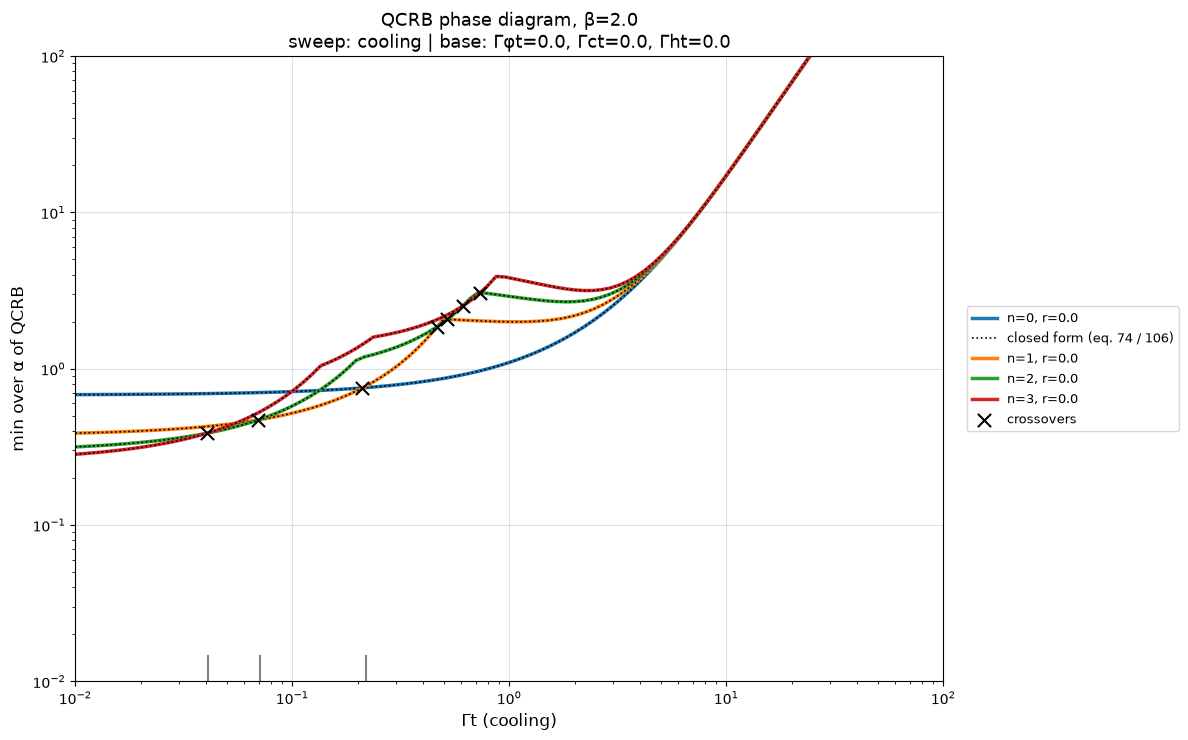

In [9]:
function crossings(x, y1, y2)
    out = Tuple{Float64,Float64}[]
    for k in 1:(length(x)-1)
        d1 = y1[k] - y2[k]; d2 = y1[k+1] - y2[k+1]
        (isfinite(d1) && isfinite(d2) && d1 * d2 < 0) || continue
        abs(d1) + abs(d2) < 1e-3 * (y1[k] + y2[k]) && continue        # merged curves, not a real crossing
        t = d1 / (d1 - d2)
        push!(out, (10.0^((1 - t) * log10(x[k]) + t * log10(x[k+1])), 10.0^((1 - t) * log10(y1[k]) + t * log10(y1[k+1]))))
    end
    return out
end

function plot_phase_diagram(; sweep::Symbol=:cooling, β::Float64=2.0, n_vals=[0, 1, 2, 3], r_vals=[0.0],
                            base=(dephasing=0.0, cooling=0.0, heating=0.0), g_range=(1e-2, 1e2), npts::Int=100)
    gs = 10.0 .^ range(log10(g_range[1]), log10(g_range[2]), length=npts)
    αs = collect(0.05:0.01:(2.6 * exp(maximum(r_vals))))            # grid widens with squeezing (α_opt ∝ e^r)
    Vs = readout_matrices(αs)
    states = [(n, r) for n in n_vals for r in r_vals]
    ψs = Dict(s => squeezed_fock(s[1], s[2]) for s in states)
    best = Dict(s => fill(NaN, npts) for s in states)
    αopt = Dict(s => fill(NaN, npts) for s in states)
    rates(g) = (sweep == :dephasing ? g : base.dephasing, sweep == :cooling ? g : base.cooling, sweep == :heating ? g : base.heating)

    elapsed = @elapsed Threads.@threads for i in 1:npts
        Gp, Gc, Gh = rates(gs[i])
        drv = Drive(β, Gp, Gc, Gh)                                  # shared by every (n, r) at this noise point
        for s in states
            ρ, dρ = propagate(ψs[s], drv)
            sum(@view ρ[diagind(ρ)[end-4:end]]) > 1e-6 && continue  # Fock cutoff reached: leave NaN
            q = [qcrb_from_state(ρ, dρ, V) for V in Vs]
            k = argmin(q); best[s][i] = q[k]; αopt[s][i] = αs[k]
        end
    end
    @printf("%d points × %d states in %.1f s\n", npts, length(states), elapsed)
    for s in states
        nbad = count(isnan, best[s]); nedge = count(==(αs[end]), αopt[s])
        nbad > 0 && println("n=$(s[1]), r=$(s[2]): $nbad points dropped (population reached the Fock cutoff)")
        nedge > 0 && println("n=$(s[1]), r=$(s[2]): α_opt sits on the grid edge at $nedge points")
    end

    fig = figure(figsize=(12, 7.5))
    styles = ["-", "--", ":", "-."]
    no_dephasing = sweep != :dephasing && base.dephasing == 0
    for s in states
        n, r = s
        plot(gs, best[s], color="C$(findfirst(==(n), n_vals) - 1)", linestyle=styles[findfirst(==(r), r_vals)], linewidth=2.5, label="n=$n, r=$r")
        if no_dephasing
            plot(gs, [min_qcrb_theory(n; r=r, Gc=rates(g)[2], Gh=rates(g)[3], αs=αs) for g in gs], ":", color="black", linewidth=1.2,
                 label=(s == states[1] ? "closed form (eq. 74 / 106)" : nothing))
        end
    end
    cx = Float64[]; cy = Float64[]
    for r in r_vals, (nlo, nhi) in zip(n_vals[1:end-1], n_vals[2:end])
        for (x, y) in crossings(gs, best[(nhi, r)], best[(nlo, r)])
            push!(cx, x); push!(cy, y)
            @printf("crossover n=%d → n=%d (r=%.1f) at Γt = %.4f\n", nhi, nlo, r, x)
        end
    end
    isempty(cx) || scatter(cx, cy, color="black", s=90, zorder=5, marker="x", label="crossovers")
    if sweep == :cooling && base.heating == 0 && base.dephasing == 0
        for r in r_vals, n in n_vals[2:end]
            axvline(crossover_first_order(n, n - 1; r=r), ymax=0.04, color="grey", linewidth=1.5)
        end
    end
    xscale("log"); yscale("log"); xlim(g_range...); ylim(1e-2, 1e2)
    xlabel("Γt ($(sweep))", fontsize=12); ylabel("min over α of QCRB", fontsize=12)
    title("QCRB phase diagram, β=$β\nsweep: $(sweep) | base: Γφt=$(base.dephasing), Γct=$(base.cooling), Γht=$(base.heating)", fontsize=13)
    grid(alpha=0.4); legend(fontsize=9, loc="center left", bbox_to_anchor=(1.02, 0.5)); tight_layout()
    display(fig); close(fig)
    return (gs=gs, best=best, αopt=αopt)
end

res_cool = plot_phase_diagram(sweep=:cooling);

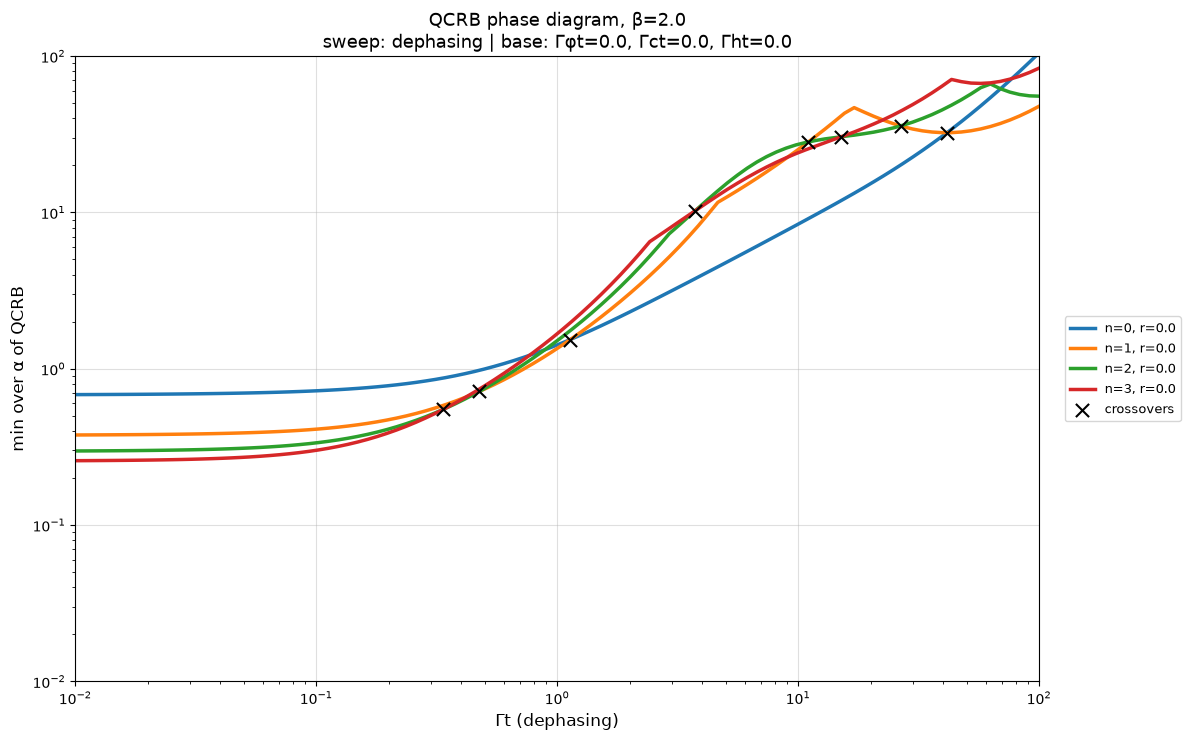

100 points × 4 states in 2.4 s
crossover n=1 → n=0 (r=0.0) at Γt = 1.1337
crossover n=1 → n=0 (r=0.0) at Γt = 41.4056
crossover n=2 → n=1 (r=0.0) at Γt = 0.4743
crossover n=2 → n=1 (r=0.0) at Γt = 10.9979
crossover n=2 → n=1 (r=0.0) at Γt = 26.5980
crossover n=3 → n=2 (r=0.0) at Γt = 0.3367
crossover n=3 → n=2 (r=0.0) at Γt = 3.7253
crossover n=3 → n=2 (r=0.0) at Γt = 15.0839


In [10]:
res_deph = plot_phase_diagram(sweep=:dephasing);

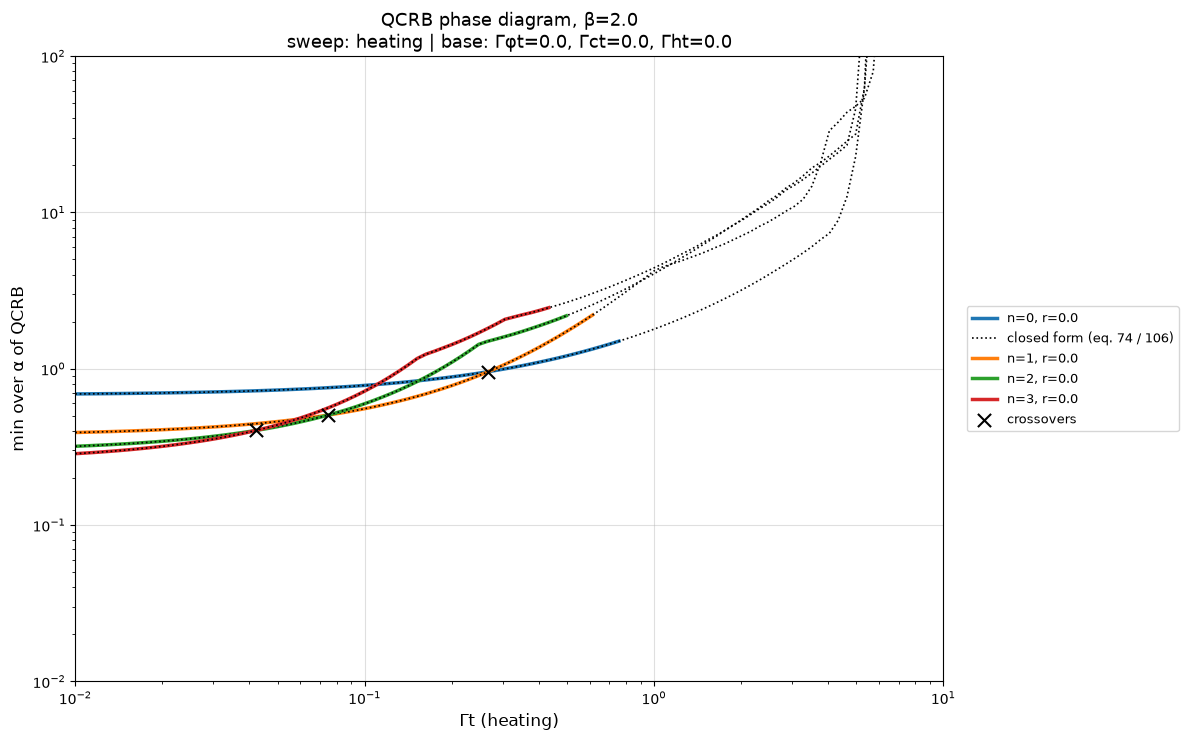

100 points × 4 states in 3.5 s
n=0, r=0.0: 37 points dropped (population reached the Fock cutoff)
n=1, r=0.0: 40 points dropped (population reached the Fock cutoff)
n=2, r=0.0: 43 points dropped (population reached the Fock cutoff)
n=3, r=0.0: 45 points dropped (population reached the Fock cutoff)
crossover n=1 → n=0 (r=0.0) at Γt = 0.2675
crossover n=2 → n=1 (r=0.0) at Γt = 0.0750
crossover n=3 → n=2 (r=0.0) at Γt = 0.0421


In [11]:
res_heat = plot_phase_diagram(sweep=:heating, g_range=(1e-2, 1e1));

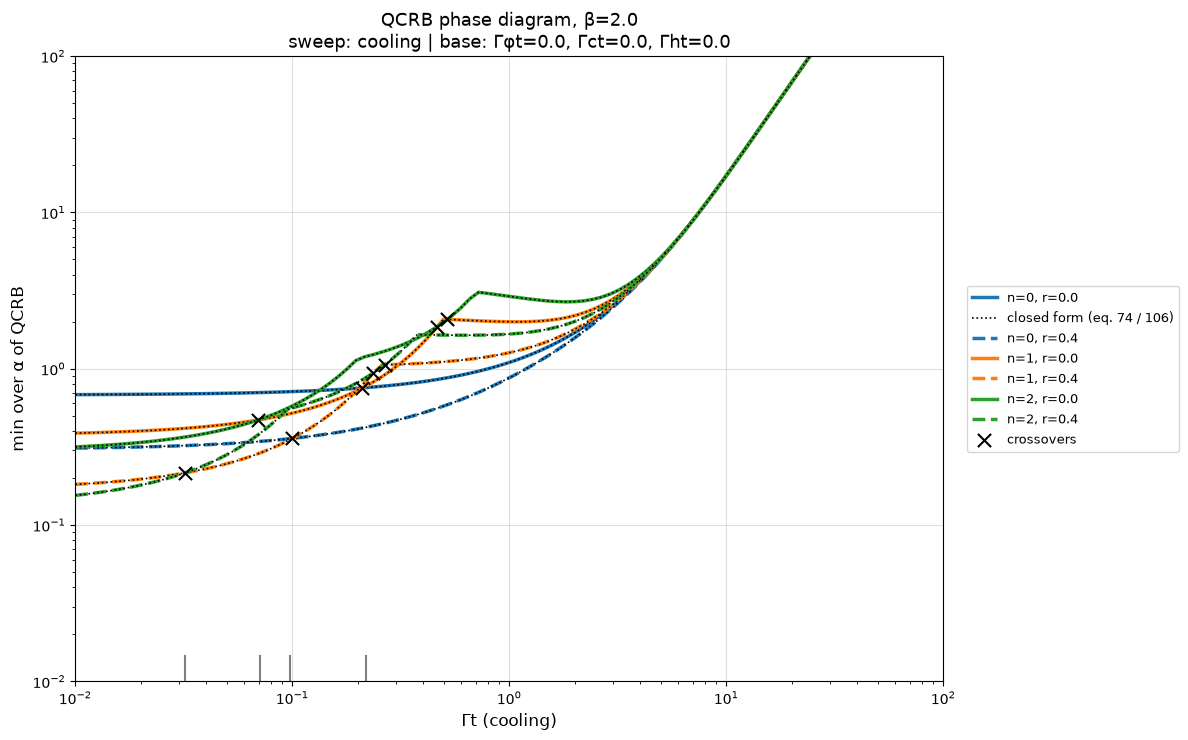

100 points × 6 states in 8.8 s
crossover n=1 → n=0 (r=0.0) at Γt = 0.2105
crossover n=2 → n=1 (r=0.0) at Γt = 0.0696
crossover n=2 → n=1 (r=0.0) at Γt = 0.4652
crossover n=2 → n=1 (r=0.0) at Γt = 0.5174
crossover n=1 → n=0 (r=0.4) at Γt = 0.1001
crossover n=2 → n=1 (r=0.4) at Γt = 0.0319
crossover n=2 → n=1 (r=0.4) at Γt = 0.2356
crossover n=2 → n=1 (r=0.4) at Γt = 0.2660


In [12]:
res_sq = plot_phase_diagram(sweep=:cooling, n_vals=[0, 1, 2], r_vals=[0.0, 0.4]);

## 6. Strong dephasing: numerics versus eq. 139

Eq. 139 predicts `min QCRB → K_n (Γφt)²` with a state-dependent constant `K_n` that does not depend on β. The table shows `min QCRB / (Γφt)²` from the engine.

In [13]:
αs_wide = collect(0.05:0.01:3.5); Vs_wide = readout_matrices(αs_wide)
println("eq. 139 K_n, n = 0..3:              ", join([@sprintf("%.4f", dephasing_K(n)) for n in 0:3], "  "))
for β in (0.1, 1.0, 2.0), G in (100.0, 1000.0)
    drv = Drive(β, G, 0.0, 0.0)
    vals = Float64[]; edge = false
    for n in 0:3
        ρ, dρ = propagate(squeezed_fock(n, 0.0), drv)
        q = [qcrb_from_state(ρ, dρ, V) for V in Vs_wide]
        push!(vals, minimum(q) / G^2); edge |= argmin(q) == length(αs_wide)
    end
    @printf("engine  β = %.1f, Γφt = %6.0f:      %s%s\n", β, G, join([@sprintf("%.4f", v) for v in vals], "  "), edge ? "   (α_opt on grid edge)" : "")
end

eq. 139 K_n, n = 0..3:              0.1699  0.0937  0.0740  0.0641
engine  β = 0.1, Γφt =    100:      0.1606  0.0803  0.0572  0.0450
engine  β = 0.1, Γφt =   1000:      0.1599  0.0793  0.0561  0.0438
engine  β = 1.0, Γφt =    100:      0.0261  0.0071  0.0043  0.0034
engine  β = 1.0, Γφt =   1000:      0.0218  0.0049  0.0023  0.0015
engine  β = 2.0, Γφt =    100:      0.0105  0.0048  0.0055  0.0084
engine  β = 2.0, Γφt =   1000:      0.0063  0.0014  0.0007  0.0005


## Notes

**Why 1104 showed no plot.** Its saved outputs are errors from an older environment: `matplotlib` could not be imported (PyCall pointed at `/usr/bin/python3`) and `IonSim` was not in the project, so every later cell failed with `UndefVarError`. Both are fixed in the current environment. The last cell (the "ultra-fast" phase diagram) was never run; when run it draws an empty frame, because it shifts the perturbed state by its *own* mean displacement, which removes the signal phase and sends every QCRB above the plotted range.

**Where the code and the derivation differ.**

- Cooling, heating and squeezing: the engine reproduces eq. 33 / 74 / 106 (table in Sec. 3).
- Dephasing, moderate noise: the static β_eff model (eq. 126 / 134) is above the exact result once `Γφt ≳ 0.3` (first plot in Sec. 4).
- Dephasing, strong noise: the `(Γφt)²` scaling of eq. 139 holds, but the constant depends on β and is below `K_n` (Sec. 6).
- Heating sweeps: without cooling the phonon number grows like `e^{Γht}`, so with β = 2 the 51 Fock levels are only enough up to `Γht ≈ 0.5`. Points beyond that are dropped instead of plotted; the closed form (dotted) continues.
- The exact crossovers are slightly below the first-order values of eq. 103 (0.211 / 0.070 / 0.040 against 0.218 / 0.071 / 0.041).

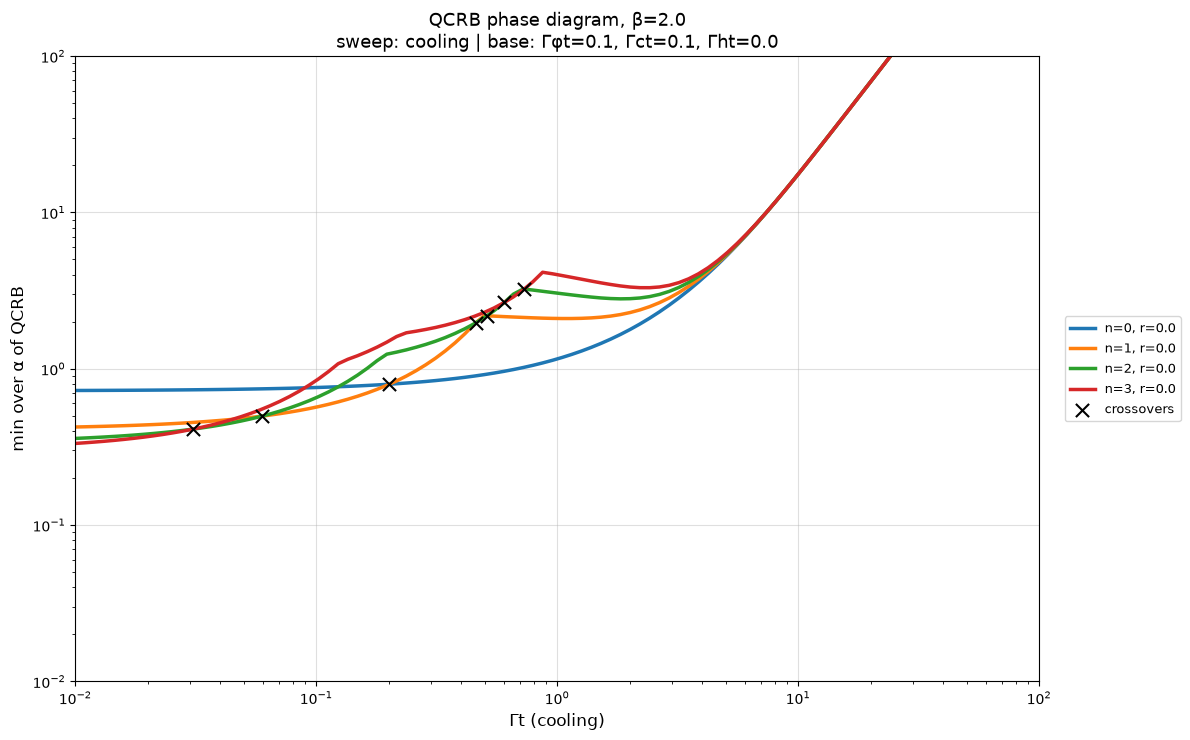

100 points × 4 states in 5.7 s
crossover n=1 → n=0 (r=0.0) at Γt = 0.2009
crossover n=2 → n=1 (r=0.0) at Γt = 0.0597
crossover n=2 → n=1 (r=0.0) at Γt = 0.4604
crossover n=2 → n=1 (r=0.0) at Γt = 0.5097
crossover n=3 → n=2 (r=0.0) at Γt = 0.0308
crossover n=3 → n=2 (r=0.0) at Γt = 0.6032
crossover n=3 → n=2 (r=0.0) at Γt = 0.7287


In [14]:
res_cool = plot_phase_diagram(sweep=:cooling, base=(dephasing=0.1, cooling=0.1, heating=0.0));

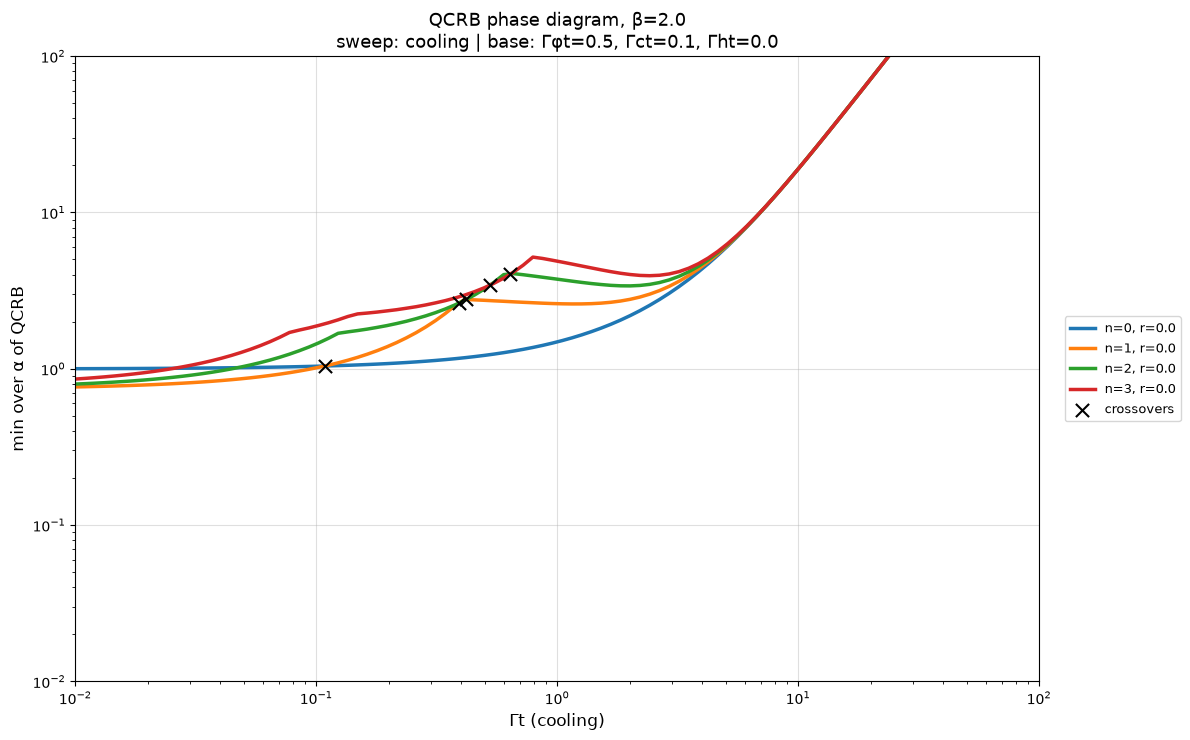

100 points × 4 states in 5.4 s
crossover n=1 → n=0 (r=0.0) at Γt = 0.1084
crossover n=2 → n=1 (r=0.0) at Γt = 0.3929
crossover n=2 → n=1 (r=0.0) at Γt = 0.4190
crossover n=3 → n=2 (r=0.0) at Γt = 0.5246
crossover n=3 → n=2 (r=0.0) at Γt = 0.6398


In [15]:
res_cool = plot_phase_diagram(sweep=:cooling, base=(dephasing=0.5, cooling=0.1, heating=0.0));

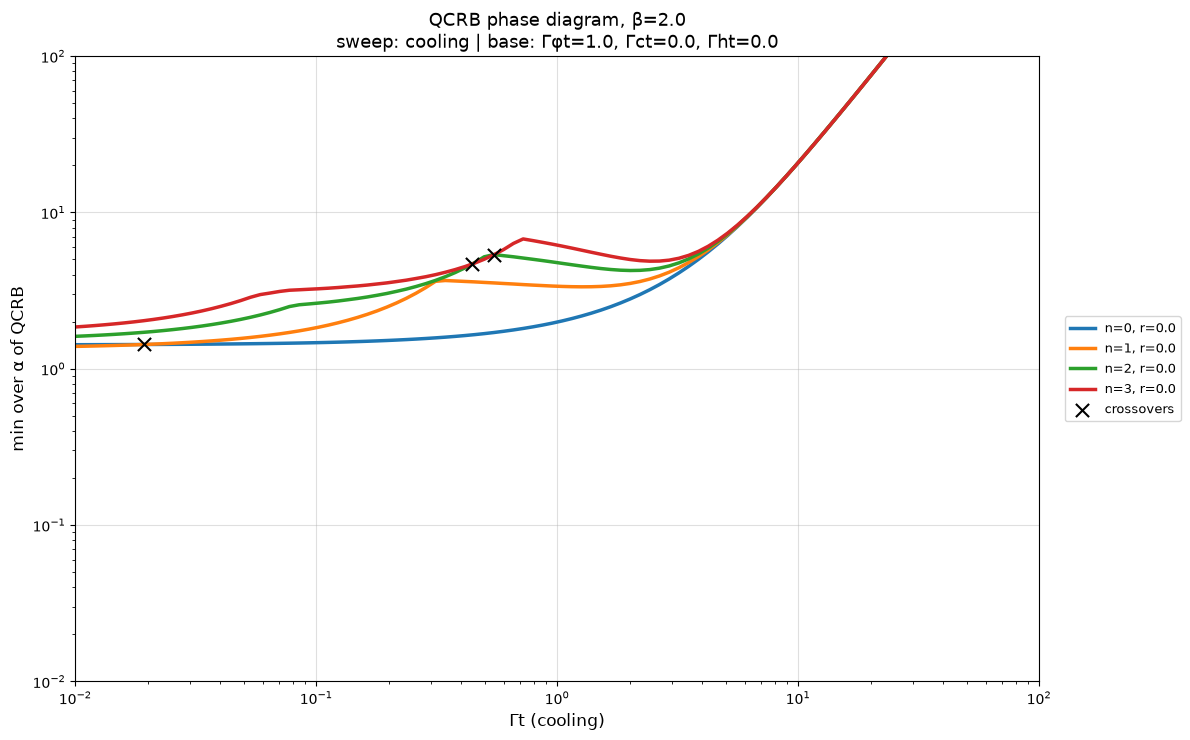

100 points × 4 states in 5.4 s
crossover n=1 → n=0 (r=0.0) at Γt = 0.0193
crossover n=3 → n=2 (r=0.0) at Γt = 0.4424
crossover n=3 → n=2 (r=0.0) at Γt = 0.5473


In [16]:
res_cool = plot_phase_diagram(sweep=:cooling, base=(dephasing=1.0, cooling=0.0, heating=0.0));

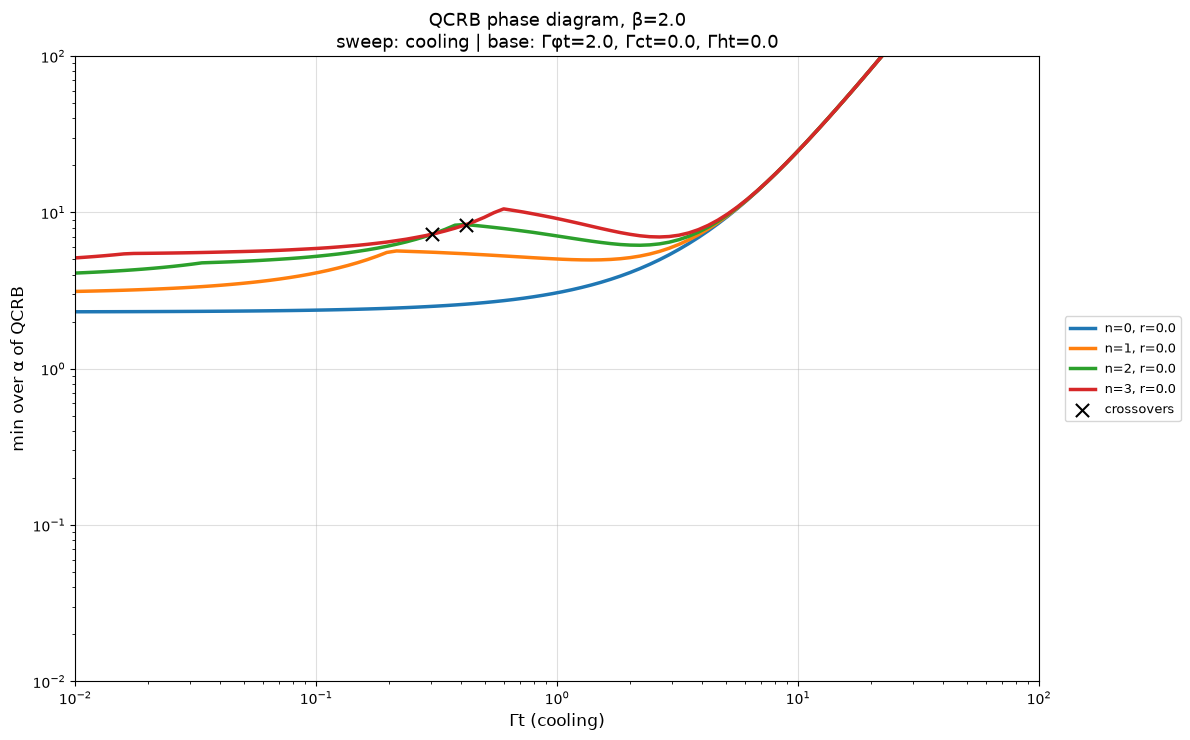

100 points × 4 states in 5.7 s
crossover n=3 → n=2 (r=0.0) at Γt = 0.3029
crossover n=3 → n=2 (r=0.0) at Γt = 0.4179


In [17]:
res_cool = plot_phase_diagram(sweep=:cooling, base=(dephasing=2.0, cooling=0.0, heating=0.0));

Computing 2D Multi-Channel Noise Atlas (40x40)...


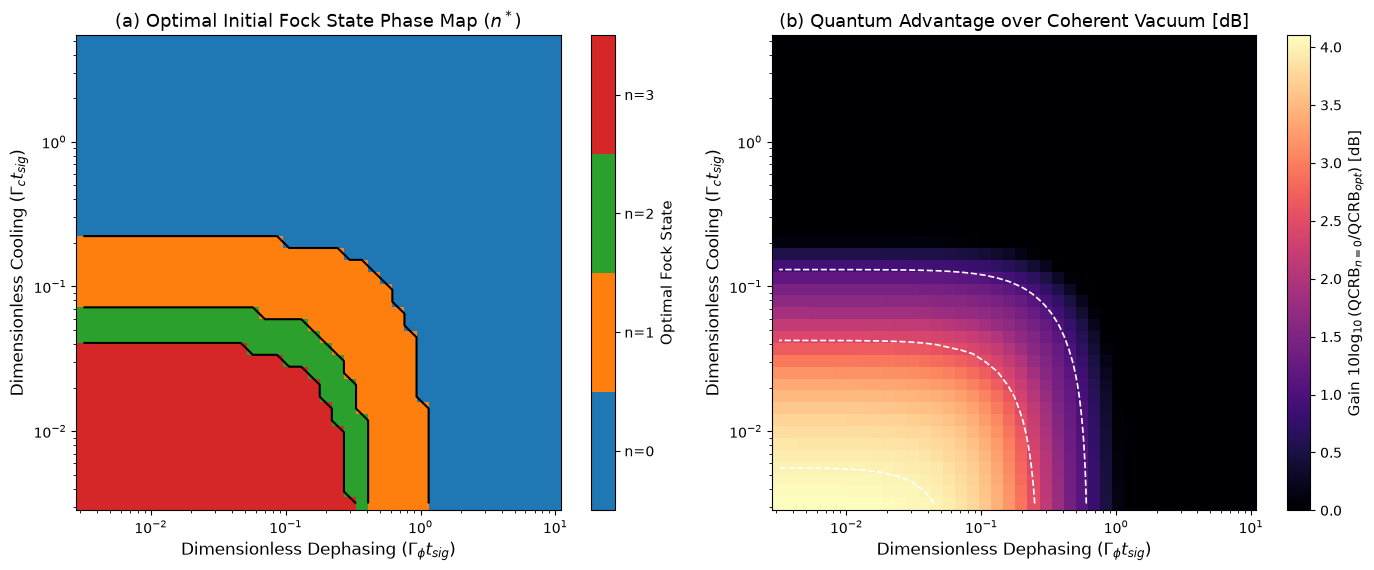

In [18]:
ENV["MPLBACKEND"] = "agg"
using LinearAlgebra
using PyPlot

# 1. Exact Block-Diagonal Noise Channel E_noise(tau)
function build_exact_noise_blocks(N_cut::Int, g_phi::Float64, g_c::Float64, g_h::Float64, tau::Float64)
    blocks = Vector{Matrix{Float64}}(undef, N_cut + 1)
    for k in 0:N_cut
        dim = N_cut + 1 - k
        T = zeros(Float64, dim, dim)
        for m in 0:(dim - 1)
            idx = m + 1
            # Heaviside cutoff at top of Fock ladder for exact trace conservation
            heat_diag = (m + k < N_cut) ? (2m + k + 2) : (m + k == N_cut ? (m + 1) : 0)
            T[idx, idx] = -(0.5 * g_c * (2m + k) + 0.5 * g_h * heat_diag + 0.5 * g_phi * k^2)
            if m + 1 < dim
                T[idx, idx + 1] = g_c * sqrt((m + 1) * (m + k + 1))
            end
            if m >= 1
                T[idx, idx - 1] = g_h * sqrt(m * (m + k))
            end
        end
        blocks[k + 1] = exp(tau .* T)
    end
    return blocks
end

function apply_noise_blocks!(rho::Matrix{Float64}, blocks::Vector{Matrix{Float64}}, buf::Vector{Float64})
    N_cut = size(rho, 1) - 1
    for k in 0:N_cut
        dim = N_cut + 1 - k
        E_k = blocks[k + 1]
        @inbounds for m in 1:dim
            s = 0.0
            for n in 1:dim
                s += E_k[m, n] * rho[n, n + k]
            end
            buf[m] = s
        end
        @inbounds for m in 1:dim
            rho[m, m + k] = buf[m]
            if k > 0
                rho[m + k, m] = buf[m] # Both rho and drho are real & symmetric
            end
        end
    end
end

# 2. Second-Order Strang Propagation with Co-Propagated Derivative d_rho
function propagate_strang_all_n!(q_vals::Vector{Float64}, n_list::Vector{Int},
                                 g_phi::Float64, g_c::Float64, g_h::Float64,
                                 beta::Float64, N_cut::Int, G_mat::Matrix{Float64},
                                 cos_ops::Vector{Matrix{Float64}}, sin_ops::Vector{Matrix{Float64}},
                                 rho::Matrix{Float64}, drho::Matrix{Float64},
                                 tmp1::Matrix{Float64}, tmp2::Matrix{Float64}, buf::Vector{Float64})
    g_max = max(g_phi, g_c, g_h)
    S = max(64, Int(ceil(6.0 * g_max)))
    dt = 1.0 / S
    d_beta = beta / S

    D_step = exp(d_beta .* G_mat)
    D_step_T = collect(transpose(D_step))
    blocks_half = build_exact_noise_blocks(N_cut, g_phi, g_c, g_h, 0.5 * dt)
    blocks_full = build_exact_noise_blocks(N_cut, g_phi, g_c, g_h, dt)

    for (idx_n, n_fock) in enumerate(n_list)
        fill!(rho, 0.0)
        fill!(drho, 0.0)
        rho[n_fock + 1, n_fock + 1] = 1.0

        # Initial half noise step
        apply_noise_blocks!(rho, blocks_half, buf)

        for s in 1:S
            # Drive rho: tmp2 = D * rho * D^T
            mul!(tmp1, D_step, rho)
            mul!(tmp2, tmp1, D_step_T)

            # Drive drho: drho = D * drho * D^T + (1/S) * [G, tmp2]
            # Since G^T = -G and tmp2^T = tmp2, [G, tmp2] = G*tmp2 + (G*tmp2)^T
            mul!(tmp1, D_step, drho)
            mul!(drho, tmp1, D_step_T)
            mul!(tmp1, G_mat, tmp2)
            @inbounds for j in 1:(N_cut + 1), i in 1:(N_cut + 1)
                drho[i, j] += (tmp1[i, j] + tmp1[j, i]) / S
            end
            rho .= tmp2

            # Noise step (full on interior, half on final step)
            b_use = (s < S) ? blocks_full : blocks_half
            apply_noise_blocks!(rho, b_use, buf)
            apply_noise_blocks!(drho, b_use, buf)
        end

        # Evaluate QCRB_unified across readout alpha
        min_qcrb = Inf
        for idx in eachindex(cos_ops)
            Cr = dot(cos_ops[idx], rho)
            Ci = dot(sin_ops[idx], rho)
            dCr = dot(cos_ops[idx], drho)
            dCi = dot(sin_ops[idx], drho)

            abs_C2 = min(0.99999999, Cr^2 + Ci^2)
            abs_dC2 = dCr^2 + dCi^2
            re_conj = Cr * dCr + Ci * dCi

            qfi = abs_dC2 + (re_conj^2) / (1.0 - abs_C2)
            if qfi > 1e-12
                qcrb = 1.0 / qfi
                if qcrb < min_qcrb
                    min_qcrb = qcrb
                end
            end
        end
        q_vals[idx_n] = min_qcrb
    end
end

# 3. 2D Multi-Channel Atlas Generator
function plot_2d_noise_atlas(; beta::Float64=2.0, N_cut::Int=45, grid_res::Int=40)
    # Build generator G = a^\dagger - a and X = a^\dagger + a
    G_mat = zeros(Float64, N_cut + 1, N_cut + 1)
    X_mat = zeros(Float64, N_cut + 1, N_cut + 1)
    for m in 1:N_cut
        val = sqrt(Float64(m))
        G_mat[m + 1, m] = val
        G_mat[m, m + 1] = -val
        X_mat[m + 1, m] = val
        X_mat[m, m + 1] = val
    end

    # Readout operator D(2i*alpha) = exp(2i*alpha*(a^\dagger + a))
    alphas = collect(0.05:0.015:1.8)
    eig_X = eigen(Symmetric(X_mat))
    V, lam = eig_X.vectors, eig_X.values
    cos_ops = [Symmetric(V * Diagonal(cos.(2.0 .* a .* lam)) * V') |> Matrix for a in alphas]
    sin_ops = [Symmetric(V * Diagonal(sin.(2.0 .* a .* lam)) * V') |> Matrix for a in alphas]

    g_phi_axis = 10.0 .^ range(-2.5, 1.0, length=grid_res)
    g_cool_axis = 10.0 .^ range(-2.5, 0.7, length=grid_res)

    n_list = [0, 1, 2, 3]
    winner_map = zeros(Int, grid_res, grid_res)
    gain_db_map = zeros(Float64, grid_res, grid_res)

    # Pre-allocate buffers
    rho = zeros(Float64, N_cut + 1, N_cut + 1)
    drho = zeros(Float64, N_cut + 1, N_cut + 1)
    tmp1 = zeros(Float64, N_cut + 1, N_cut + 1)
    tmp2 = zeros(Float64, N_cut + 1, N_cut + 1)
    buf = zeros(Float64, N_cut + 1)
    q_vals = zeros(Float64, length(n_list))

    println("Computing 2D Multi-Channel Noise Atlas ($(grid_res)x$(grid_res))...")
    for (i, gc) in enumerate(g_cool_axis)
        for (j, gphi) in enumerate(g_phi_axis)
            propagate_strang_all_n!(q_vals, n_list, gphi, gc, 0.0, beta, N_cut,
                                    G_mat, cos_ops, sin_ops, rho, drho, tmp1, tmp2, buf)
            best_idx = argmin(q_vals)
            winner_map[i, j] = n_list[best_idx]
            gain_db_map[i, j] = max(0.0, 10.0 * log10(q_vals[1] / q_vals[best_idx]))
        end
    end

    fig, (ax1, ax2) = subplots(1, 2, figsize=(14, 5.8))

    # Panel A: Discrete 4-Color Optimal Fock State Map
    cmap_discrete = PyPlot.matplotlib.colors.ListedColormap(["#1f77b4", "#ff7f0e", "#2ca02c", "#d62728"])
    im1 = ax1.pcolormesh(g_phi_axis, g_cool_axis, winner_map, cmap=cmap_discrete, vmin=-0.5, vmax=3.5, shading="auto")
    ax1.contour(g_phi_axis, g_cool_axis, winner_map, levels=[0.5, 1.5, 2.5], colors="black", linewidths=1.5)
    ax1.set_xscale("log"); ax1.set_yscale("log")
    ax1.set_xlabel(L"Dimensionless Dephasing ($\Gamma_\phi t_{sig}$)", fontsize=12)
    ax1.set_ylabel(L"Dimensionless Cooling ($\Gamma_c t_{sig}$)", fontsize=12)
    ax1.set_title(L"(a) Optimal Initial Fock State Phase Map ($n^*$)", fontsize=13)
    cbar1 = fig.colorbar(im1, ax=ax1, ticks=[0, 1, 2, 3])
    cbar1.ax.set_yticklabels(["n=0", "n=1", "n=2", "n=3"])
    cbar1.set_label("Optimal Fock State", fontsize=11)

    # Panel B: Metrological Gain (dB) over Vacuum (n=0)
    im2 = ax2.pcolormesh(g_phi_axis, g_cool_axis, gain_db_map, cmap="magma", vmin=0.0, shading="auto")
    cs = ax2.contour(g_phi_axis, g_cool_axis, gain_db_map, levels=[1.0, 2.5, 4.0], colors="white", linewidths=1.2, linestyles="--")
    ax2.clabel(cs, inline=true, fontsize=9, fmt="%.1f dB")
    ax2.set_xscale("log"); ax2.set_yscale("log")
    ax2.set_xlabel(L"Dimensionless Dephasing ($\Gamma_\phi t_{sig}$)", fontsize=12)
    ax2.set_ylabel(L"Dimensionless Cooling ($\Gamma_c t_{sig}$)", fontsize=12)
    ax2.set_title("(b) Quantum Advantage over Coherent Vacuum [dB]", fontsize=13)
    cbar2 = fig.colorbar(im2, ax=ax2)
    cbar2.set_label(L"Gain $10\log_{10}(\mathrm{QCRB}_{n=0} / \mathrm{QCRB}_{opt})$ [dB]", fontsize=11)

    tight_layout()
    display(fig)
end

plot_2d_noise_atlas()

Computing High-Res 2D Multi-Channel Noise Atlas (60x60, beta=1.0)...


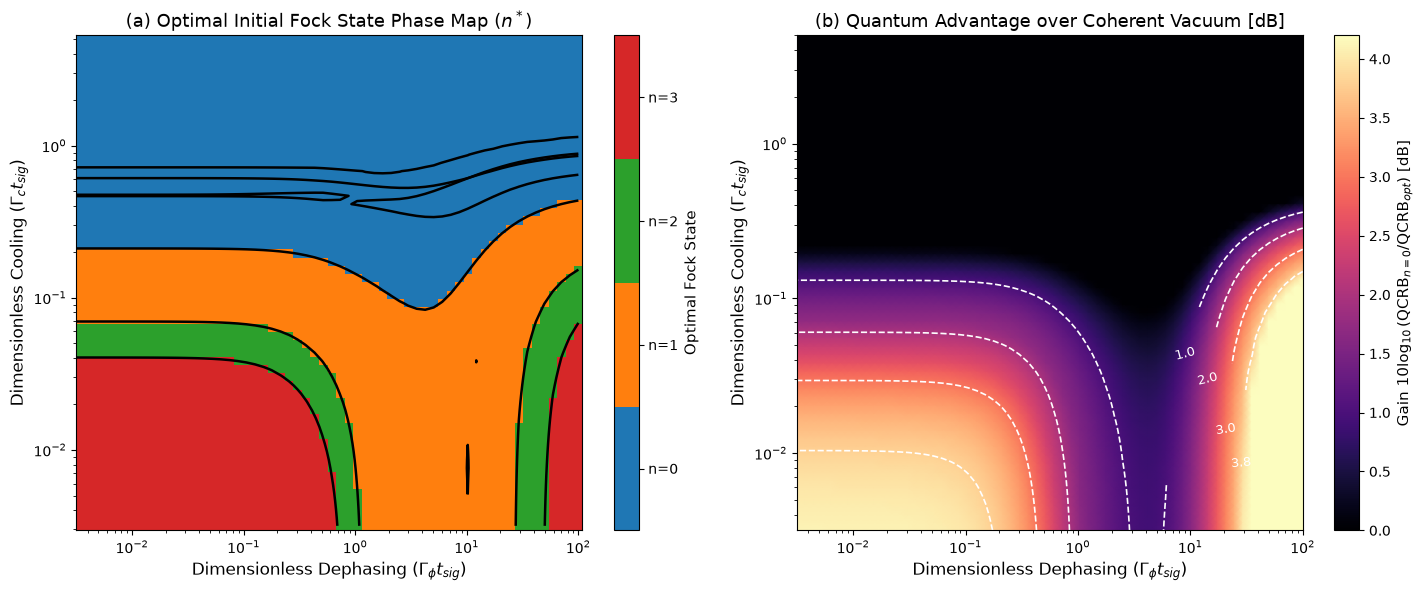

In [19]:
# 3. 2D Multi-Channel Atlas Generator (Smooth Boundaries & Zeno Regime)
function plot_2d_noise_atlas(; beta::Float64=1.0, N_cut::Int=45, grid_res::Int=60)
    G_mat = zeros(Float64, N_cut + 1, N_cut + 1)
    X_mat = zeros(Float64, N_cut + 1, N_cut + 1)
    for m in 1:N_cut
        val = sqrt(Float64(m))
        G_mat[m + 1, m] = val
        G_mat[m, m + 1] = -val
        X_mat[m + 1, m] = val
        X_mat[m, m + 1] = val
    end

    alphas = collect(0.05:0.015:1.8)
    eig_X = eigen(Symmetric(X_mat))
    V, lam = eig_X.vectors, eig_X.values
    cos_ops = [Symmetric(V * Diagonal(cos.(2.0 .* a .* lam)) * V') |> Matrix for a in alphas]
    sin_ops = [Symmetric(V * Diagonal(sin.(2.0 .* a .* lam)) * V') |> Matrix for a in alphas]

    # Sweep dephasing up to 10^2 to capture both intermediate diffusion and deep Zeno pinning
    g_phi_axis = 10.0 .^ range(-2.5, 2.0, length=grid_res)
    g_cool_axis = 10.0 .^ range(-2.5, 0.7, length=grid_res)

    n_list = [0, 1, 2, 3]
    winner_map = zeros(Int, grid_res, grid_res)
    gain_db_map = zeros(Float64, grid_res, grid_res)
    q_all = zeros(Float64, 4, grid_res, grid_res)

    rho = zeros(Float64, N_cut + 1, N_cut + 1)
    drho = zeros(Float64, N_cut + 1, N_cut + 1)
    tmp1 = zeros(Float64, N_cut + 1, N_cut + 1)
    tmp2 = zeros(Float64, N_cut + 1, N_cut + 1)
    buf = zeros(Float64, N_cut + 1)
    q_vals = zeros(Float64, length(n_list))

    println("Computing High-Res 2D Multi-Channel Noise Atlas ($(grid_res)x$(grid_res), beta=$(beta))...")
    for (i, gc) in enumerate(g_cool_axis)
        for (j, gphi) in enumerate(g_phi_axis)
            propagate_strang_all_n!(q_vals, n_list, gphi, gc, 0.0, beta, N_cut,
                                    G_mat, cos_ops, sin_ops, rho, drho, tmp1, tmp2, buf)
            q_all[:, i, j] .= q_vals
            best_idx = argmin(q_vals)
            winner_map[i, j] = n_list[best_idx]
            gain_db_map[i, j] = max(0.0, 10.0 * log10(q_vals[1] / q_vals[best_idx]))
        end
    end

    fig, (ax1, ax2) = subplots(1, 2, figsize=(14.5, 6.0))

    # Panel A: Discrete 4-Color Optimal Fock State Map with Smooth Zero-Crossing Contours
    cmap_discrete = PyPlot.matplotlib.colors.ListedColormap(["#1f77b4", "#ff7f0e", "#2ca02c", "#d62728"])
    im1 = ax1.pcolormesh(g_phi_axis, g_cool_axis, winner_map, cmap=cmap_discrete, vmin=-0.5, vmax=3.5, shading="nearest")
    
    # Plot smooth exact crossover boundaries where log10(QCRB_n) == log10(QCRB_{n-1})
    for n_idx in 2:4
        diff_map = log10.(q_all[n_idx, :, :]) .- log10.(q_all[n_idx - 1, :, :])
        ax1.contour(g_phi_axis, g_cool_axis, diff_map, levels=[0.0], colors="black", linewidths=1.8)
    end

    ax1.set_xscale("log"); ax1.set_yscale("log")
    ax1.set_xlabel(L"Dimensionless Dephasing ($\Gamma_\phi t_{sig}$)", fontsize=12)
    ax1.set_ylabel(L"Dimensionless Cooling ($\Gamma_c t_{sig}$)", fontsize=12)
    ax1.set_title(L"(a) Optimal Initial Fock State Phase Map ($n^*$)", fontsize=13)
    cbar1 = fig.colorbar(im1, ax=ax1, ticks=[0, 1, 2, 3])
    cbar1.ax.set_yticklabels(["n=0", "n=1", "n=2", "n=3"])
    cbar1.set_label("Optimal Fock State", fontsize=11)

    # Panel B: Metrological Gain (dB) over Vacuum (n=0)
    im2 = ax2.pcolormesh(g_phi_axis, g_cool_axis, gain_db_map, cmap="magma", vmin=0.0, vmax=4.2, shading="gouraud")
    cs = ax2.contour(g_phi_axis, g_cool_axis, gain_db_map, levels=[1.0, 2.0, 3.0, 3.8], colors="white", linewidths=1.2, linestyles="--")
    ax2.clabel(cs, inline=true, fontsize=9)
    ax2.set_xscale("log"); ax2.set_yscale("log")
    ax2.set_xlabel(L"Dimensionless Dephasing ($\Gamma_\phi t_{sig}$)", fontsize=12)
    ax2.set_ylabel(L"Dimensionless Cooling ($\Gamma_c t_{sig}$)", fontsize=12)
    ax2.set_title("(b) Quantum Advantage over Coherent Vacuum [dB]", fontsize=13)
    cbar2 = fig.colorbar(im2, ax=ax2)
    cbar2.set_label(L"Gain $10\log_{10}(\mathrm{QCRB}_{n=0} / \mathrm{QCRB}_{opt})$ [dB]", fontsize=11)

    tight_layout()
    display(fig)
end

plot_2d_noise_atlas(beta=1.0, grid_res=60)

## 7. Audit of the 2D atlas and clearer views (added 2026-11-15)

**The atlas above is numerically sound**: rechecked with α up to 4 and 51 levels, the winners and gains do not change. What it hides:

- Panel (b) is clipped at 4.2 dB. The bright strong-dephasing corner is really 8–9 dB at β = 1, and there the best state is still 50–400× worse than a noiseless vacuum sensor.
- The map depends on β (compare the β = 2 and β = 1 versions). Cooling and heating do not; dephasing does.
- Only n ≤ 3 is searched, so the red region means "n ≥ 3", not "n = 3".
- Panel (a) of the second version draws every n / n−1 crossing, including ones inside the region where n = 0 wins anyway.
- Zero-temperature damping is the photon-loss axis. For a trapped ion the usual pair is heating rate (Γc ≈ Γh) and dephasing.

**Small signals:** for β → 0, dephasing multiplies every Fock state's QCRB by the same factor 1/f², f = (2/Γφt)(1 − e^{−Γφt/2}), so the Fock ranking never changes. Everything else on the dephasing axis is a finite-signal effect of size β²(n+1).

The cells below give (1) the strong-dephasing constant with its β-dependence, (2) gain-versus-noise curves and the best Fock number, and (3) a dephasing × signal-size map.

In [21]:
# Strong dephasing: eq. 139 keeps only the phase signal. The drive also moves population out of |n> at a rate
# ∝ β²/Γφ, and the qubit contrast |C| sees it. Both terms scale as 1/(Γφt)², so the constant depends on β:
#   K_n(β) = min_α 1 / (64 [ α² V_n² + β² W_n² / (1 − V_n²) ]),
#   V_j = e^{−2α²} L_j(4α²),   W_n = (n+1)(V_{n+1} − V_n) + n (V_{n−1} − V_n).
# β → 0 gives back eq. 139. Valid while 4β²(n+1) ≪ Γφt.
function dephasing_K_beta(n::Int, β::Real; αs=0.02:0.002:4.0)
    Vj(j, α) = exp(-2α^2) * laguerre(j, 4α^2)
    best = Inf
    for α in αs
        V = Vj(n, α)
        W = (n + 1) * (Vj(n + 1, α) - V) + (n > 0 ? n * (Vj(n - 1, α) - V) : 0.0)
        best = min(best, 1 / (64 * (α^2 * V^2 + β^2 * W^2 / (1 - V^2))))
    end
    return best
end

let αs = collect(0.05:0.01:3.5), Vs = readout_matrices(collect(0.05:0.01:3.5)), G = 3000.0
    println("min QCRB / (Γφt)² at Γφt = $G: engine | K_n(β) above | eq. 139")
    for β in (0.1, 0.5, 1.0, 2.0)
        drv = Drive(β, G, 0.0, 0.0)
        @printf("β = %.1f ", β)
        for n in 0:3
            ρ, dρ = propagate(squeezed_fock(n, 0.0), drv)
            q = minimum(qcrb_from_state(ρ, dρ, V) for V in Vs) / G^2
            @printf("  n=%d: %.5f | %.5f | %.4f", n, q, dephasing_K_beta(n, β), dephasing_K_beta(n, 0.0))
        end
        println()
    end
end

min QCRB / (Γφt)² at Γφt = 3000.0: engine | K_n(β) above | eq. 139
β = 0.1   n=0: 0.15985 | 0.15973 | 0.1699  n=1: 0.07924 | 0.07917 | 0.0937  n=2: 0.05598 | 0.05593 | 0.0740  n=3: 0.04368 | 0.04363 | 0.0641
β = 0.5   n=0: 0.06340 | 0.06327 | 0.1699  n=1: 0.01633 | 0.01625 | 0.0937  n=2: 0.00806 | 0.00801 | 0.0740  n=3: 0.00503 | 0.00498 | 0.0641
β = 1.0   n=0: 0.02154 | 0.02141 | 0.1699  n=1: 0.00471 | 0.00464 | 0.0937  n=2: 0.00223 | 0.00217 | 0.0740  n=3: 0.00137 | 0.00132 | 0.0641
β = 2.0   n=0: 0.00598 | 0.00585 | 0.1699  n=1: 0.00127 | 0.00120 | 0.0937  n=2: 0.00061 | 0.00056 | 0.0740  n=3: 0.00038 | 0.00034 | 0.0641


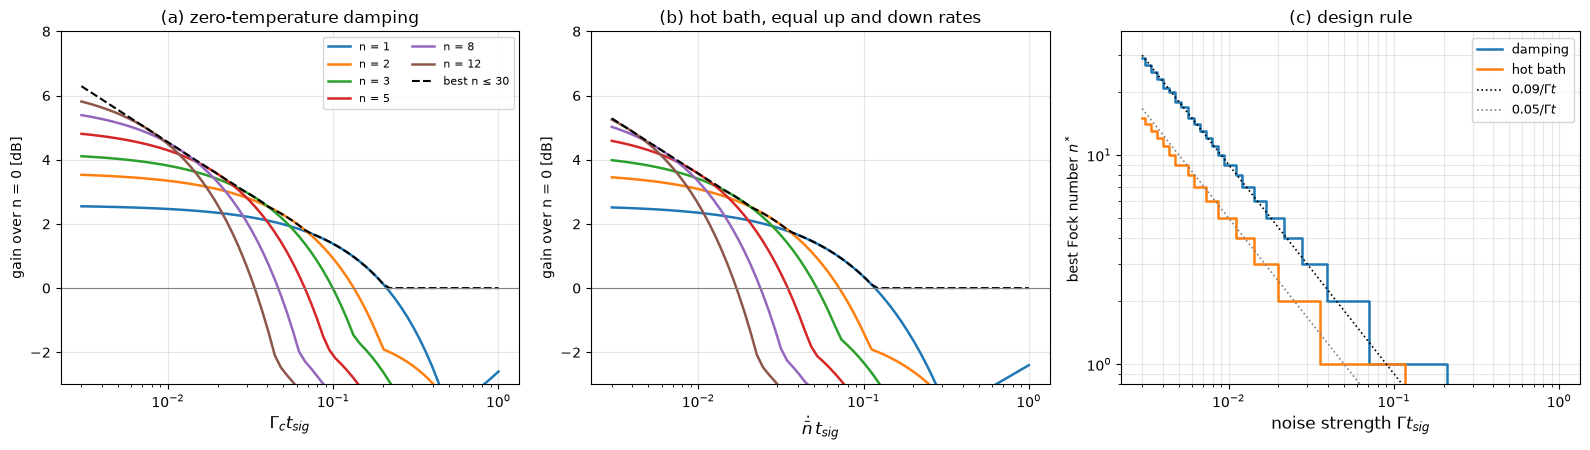

In [22]:
# Operating window: gain over the vacuum state under the same noise, from the closed form (eq. 74 / 106).
# Reads directly as "how much noise can |n> take": a line crossing 0 dB is the break-even with n = 0.
function plot_operating_window(; n_show=[1, 2, 3, 5, 8, 12], n_max=30, g_range=(3e-3, 1.0), npts=70)
    gs = 10 .^ range(log10(g_range[1]), log10(g_range[2]), length=npts)
    αs = 0.02:0.004:6.5
    channels = (("zero-temperature damping", L"\Gamma_c t_{sig}", g -> (g, 0.0)),
                ("hot bath, equal up and down rates", L"\dot{\bar n}\, t_{sig}", g -> (g, g)))
    fig, axs = subplots(1, 3, figsize=(16, 4.6))
    nstar = Dict{Int,Vector{Int}}()
    for (c, (name, xl, rates)) in enumerate(channels)
        Q = [minimum(qcrb_theory(α, n; Gc=rates(g)[1], Gh=rates(g)[2]) for α in αs) for n in 0:n_max, g in gs]
        gain = [10 * log10(Q[1, j] / Q[n+1, j]) for n in 0:n_max, j in eachindex(gs)]
        best = [maximum(gain[:, j]) for j in eachindex(gs)]
        nstar[c] = [argmax(gain[:, j]) - 1 for j in eachindex(gs)]
        ax = axs[c]
        for n in n_show
            ax.plot(gs, gain[n+1, :], lw=1.8, label="n = $n")
        end
        ax.plot(gs, best, "k--", lw=1.5, label="best n ≤ $n_max")
        ax.axhline(0, color="gray", lw=0.8)
        ax.set_xscale("log"); ax.set_ylim(-3, 8); ax.set_xlabel(xl, fontsize=12)
        ax.set_ylabel("gain over n = 0 [dB]"); ax.set_title("($('a' + c - 1)) " * name); ax.grid(alpha=0.3)
        c == 1 && ax.legend(fontsize=8, ncol=2)
    end
    ax = axs[3]
    ax.step(gs, nstar[1], where="mid", lw=1.8, label="damping")
    ax.step(gs, nstar[2], where="mid", lw=1.8, label="hot bath")
    ax.plot(gs, 0.09 ./ gs, "k:", lw=1.2, label=L"0.09/\Gamma t")
    ax.plot(gs, 0.05 ./ gs, color="gray", ls=":", lw=1.2, label=L"0.05/\Gamma t")
    ax.set_xscale("log"); ax.set_yscale("log"); ax.set_ylim(0.8, 1.3 * n_max)
    ax.set_xlabel(L"noise strength $\Gamma t_{sig}$", fontsize=12); ax.set_ylabel(L"best Fock number $n^*$")
    ax.set_title("(c) design rule"); ax.grid(alpha=0.3, which="both"); ax.legend(fontsize=9)
    tight_layout(); display(fig)
    return gs, nstar
end
plot_operating_window();

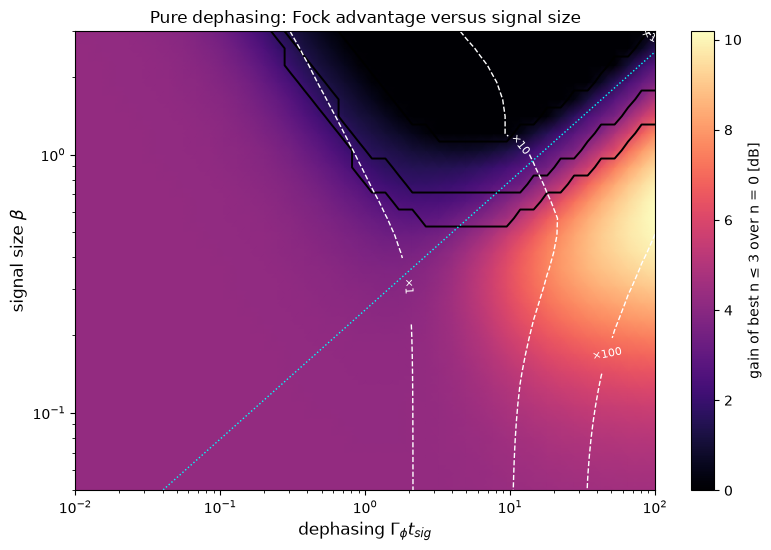

28 × 44 points × 4 states in 31.1 s; largest top-level population 1.0e-12
smallest β = 0.05: winner n* along Γφt = 3 3 3 3 3 3 3 3
largest β = 3.00: winner n* along Γφt = 3 3 3 1 0 0 0 0


In [23]:
# Dephasing is the only channel whose effect depends on the signal size β, so the natural map is (Γφt, β).
# Colour: gain of the best n ≤ 3 over n = 0 (not clipped). Black: boundaries of the winning n.
# White dashed: how much worse the best state is than a noiseless vacuum sensor (QCRB / (e/4)).
function plot_dephasing_signal_map(; n_vals=[0, 1, 2, 3], nG=44, nB=28, g_range=(1e-2, 1e2), b_range=(0.05, 3.0))
    gs = 10 .^ range(log10(g_range[1]), log10(g_range[2]), length=nG)
    βs = 10 .^ range(log10(b_range[1]), log10(b_range[2]), length=nB)
    αs = collect(0.05:0.015:2.2); Vs = readout_matrices(αs)
    Q = fill(NaN, length(n_vals), nB, nG); tails = zeros(nB, nG)
    t0 = time()
    Threads.@threads for idx in 1:(nB*nG)
        ib, ig = fldmod1(idx, nG)
        drv = Drive(βs[ib], gs[ig], 0.0, 0.0)
        for (k, n) in enumerate(n_vals)
            ρ, dρ = propagate(squeezed_fock(n, 0.0), drv)
            Q[k, ib, ig] = minimum(qcrb_from_state(ρ, dρ, V) for V in Vs)
            tails[ib, ig] = max(tails[ib, ig], sum(@view ρ[diagind(ρ)[end-4:end]]))
        end
    end
    @printf("%d × %d points × %d states in %.1f s; largest top-level population %.1e\n", nB, nG, length(n_vals), time() - t0, maximum(tails))
    best = dropdims(minimum(Q, dims=1), dims=1)
    winner = [n_vals[argmin(@view Q[:, ib, ig])] for ib in 1:nB, ig in 1:nG]
    gain = 10 .* log10.(Q[1, :, :] ./ best)
    fig, ax = subplots(figsize=(8.2, 5.6))
    im = ax.pcolormesh(gs, βs, gain, cmap="magma", shading="gouraud", vmin=0)
    cb = fig.colorbar(im, ax=ax); cb.set_label("gain of best n ≤ $(maximum(n_vals)) over n = 0 [dB]")
    ax.contour(gs, βs, winner, levels=[0.5, 1.5, 2.5], colors="black", linewidths=1.4)
    cs = ax.contour(gs, βs, log10.(best ./ (exp(1) / 4)), levels=[0.0, 1.0, 2.0, 3.0], colors="white", linewidths=1.0, linestyles="--")
    ax.clabel(cs, fmt=Dict(0.0 => "×1", 1.0 => "×10", 2.0 => "×100", 3.0 => "×1000"), fontsize=8)
    ax.plot(gs, sqrt.(gs ./ 16), color="cyan", lw=1.0, ls=":")          # 4β²(n+1) = Γφt for n = 3
    ax.set_xscale("log"); ax.set_yscale("log"); ax.set_ylim(b_range...)
    ax.set_xlabel(L"dephasing $\Gamma_\phi t_{sig}$", fontsize=12); ax.set_ylabel(L"signal size $\beta$", fontsize=12)
    ax.set_title("Pure dephasing: Fock advantage versus signal size")
    tight_layout(); display(fig)
    return (gs=gs, βs=βs, Q=Q, winner=winner, gain=gain)
end
res_map = plot_dephasing_signal_map();
for (ib, lab) in ((1, "smallest β"), (length(res_map.βs), "largest β"))
    @printf("%s = %.2f: winner n* along Γφt = %s\n", lab, res_map.βs[ib], join(res_map.winner[ib, 1:6:end], " "))
end

## 8. Heating × dephasing atlas at fixed cooling (added 2026-11-15)

In a thermal bath the two rates are tied: Γc = γ(n̄+1) and Γh = γ n̄, so Γc = Γh + γ. Raising the heating rate raises the cooling rate with it; a map with Γh above a fixed Γc is not a thermal bath (white dotted line in panel (a)). For a trapped ion n̄ is huge and γ tiny, so the realistic case is Γc ≈ Γh (`thermal=true, Gc=0`).

Closed-form break-even of n = 1 against n = 0: cooling only Γc·t = 0.211, heating only Γh·t = 0.267, hot bath Γc = Γh at 0.117.

**Is n ≤ 1 always best once Γc·t ≥ 0.1?** Without dephasing, yes: n = 2 stops beating n = 1 at Γc·t = 0.070. For small signals (β → 0) it stays true at every dephasing strength. For a finite signal it fails at strong dephasing: at β = 1, Γc·t = 0.1, n = 2 wins from Γφt ≈ 50 and n = 3 near Γφt ≈ 300, where the bound is already more than 100× the noiseless vacuum value.

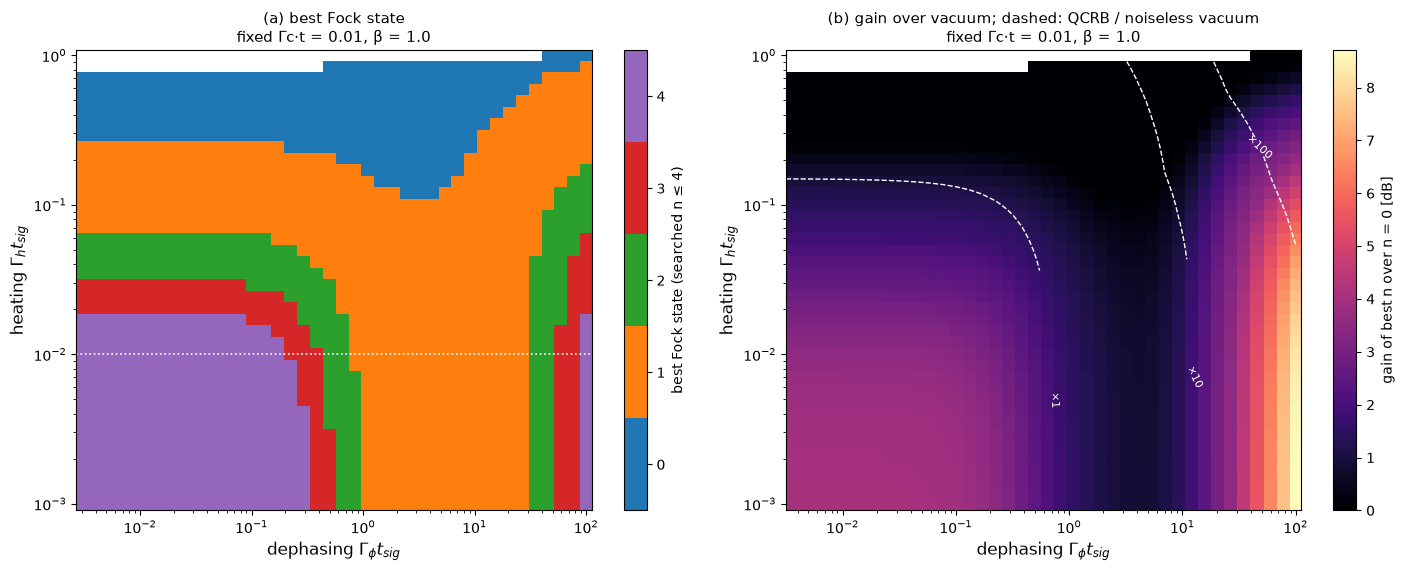

fixed Γc·t = 0.01, β = 1.00: 40 × 40 points × 5 states in 196.1 s; 55 points dropped at the Fock cutoff
  n = 1 wins somewhere up to Γh·t = 0.838
  n = 2 wins somewhere up to Γh·t = 0.170
  n = 3 wins somewhere up to Γh·t = 0.059
  n = 4 wins somewhere up to Γh·t = 0.017
fixed Γc·t = 0.1, β = 1.00: 40 × 40 points × 5 states in 186.1 s; 33 points dropped at the Fock cutoff
  n = 1 wins somewhere up to Γh·t = 0.588
  n = 2 wins somewhere up to Γh·t = 0.059
  n = 3 never wins
  n = 4 never wins
thermal bath, Γc = Γh + 0.0, β = 1.00: 40 × 40 points × 5 states in 199.0 s; 0 points dropped at the Fock cutoff
  n = 1 wins somewhere up to Γh·t = 0.242
  n = 2 wins somewhere up to Γh·t = 0.084
  n = 3 wins somewhere up to Γh·t = 0.035
  n = 4 wins somewhere up to Γh·t = 0.014
fixed Γc·t = 0.1, β = 0.01: 40 × 40 points × 5 states in 350.5 s; 0 points dropped at the Fock cutoff
  n = 1 wins somewhere up to Γh·t = 0.119
  n = 2 never wins
  n = 3 never wins
  n = 4 never wins


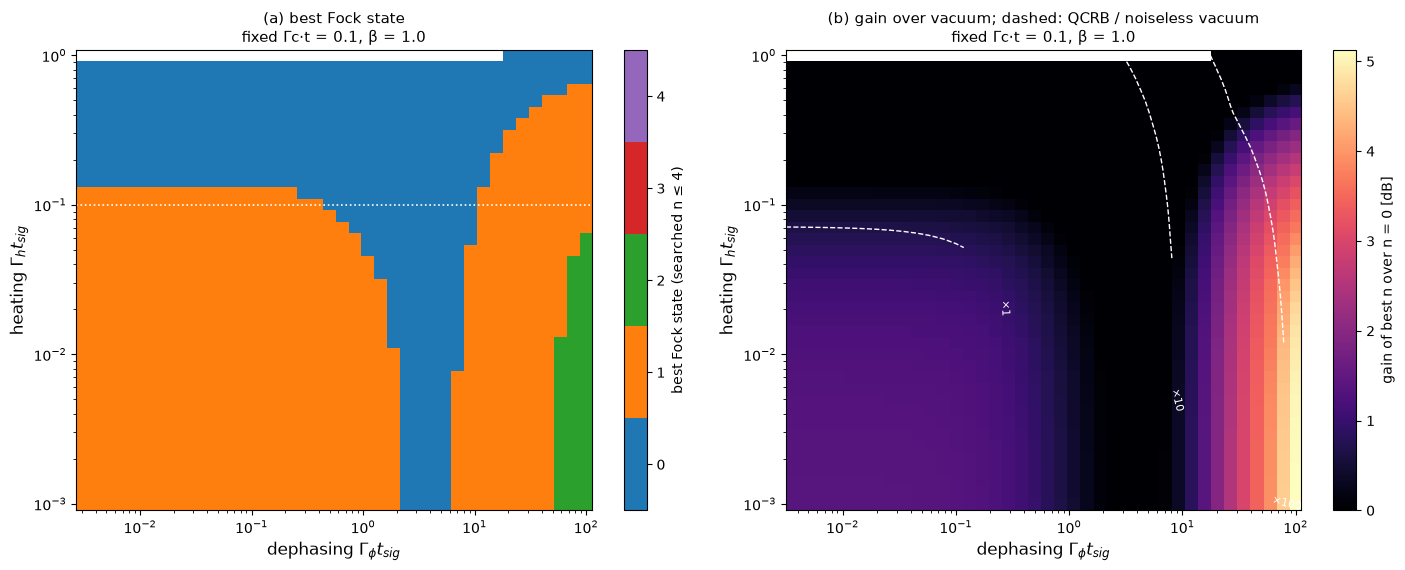

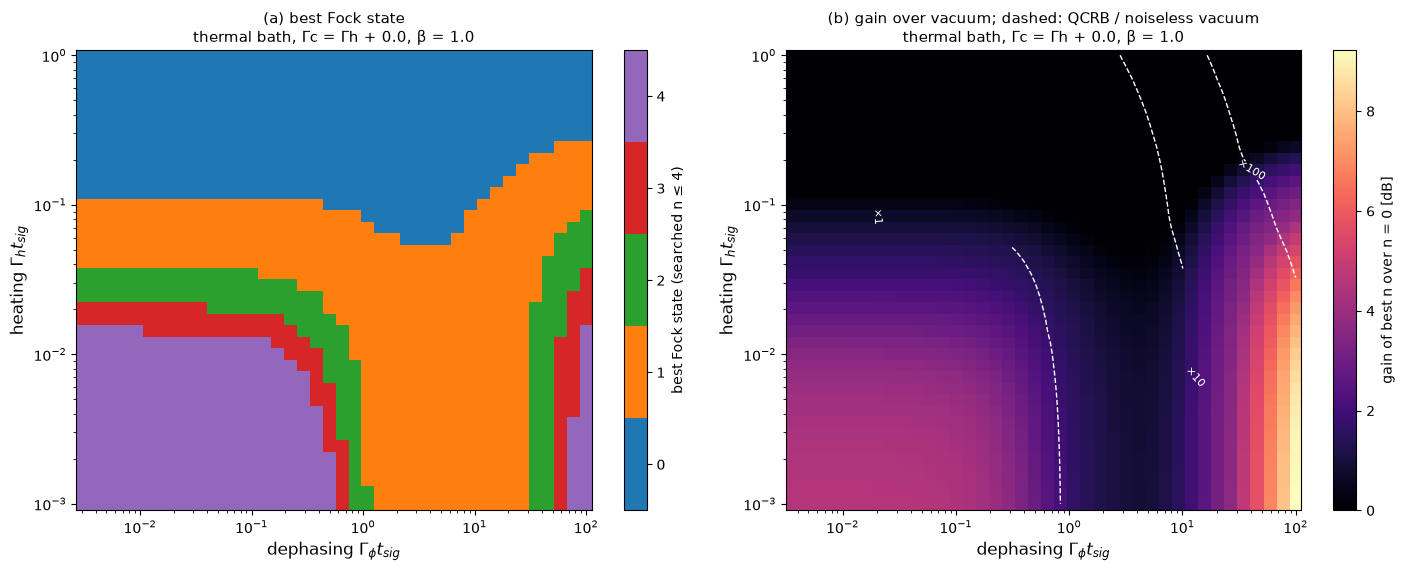

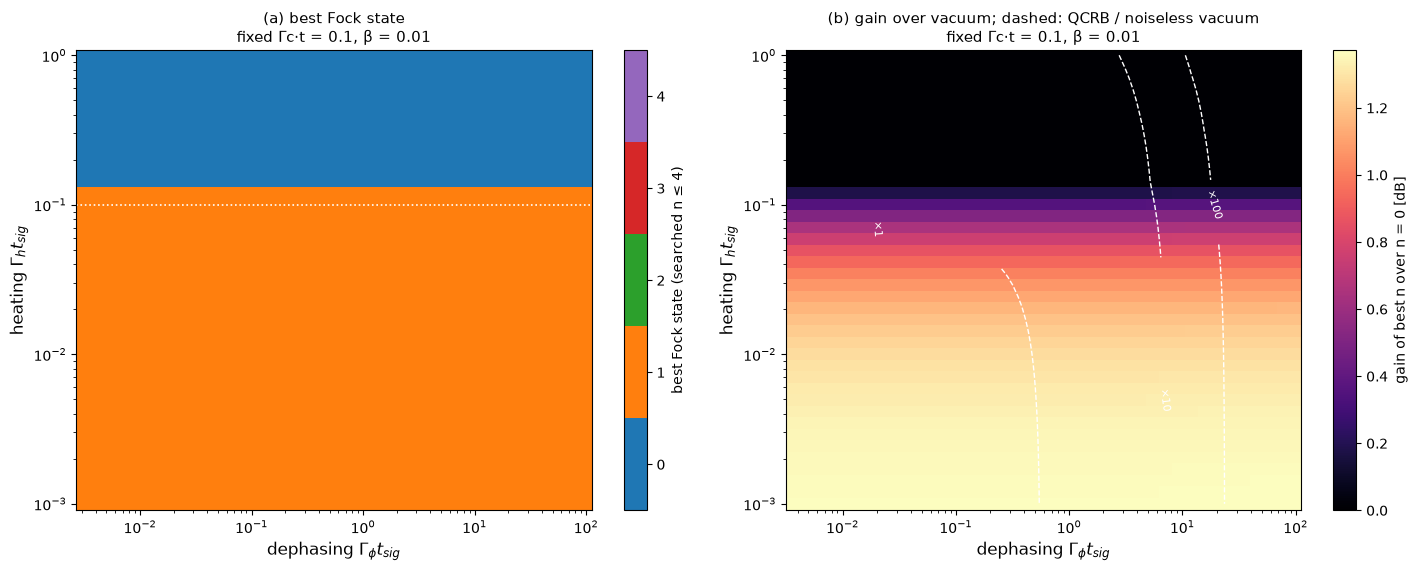

In [24]:
# Heating (y) × dephasing (x) atlas at a chosen cooling rate.
#   thermal = false : Γc·t = Gc is held fixed while Γh is swept (the literal "fix the cooling" map).
#   thermal = true  : Γc = Γh + Gc, a real thermal bath, where Gc = γ·t is the net damping. Gc = 0 is the hot-bath limit.
function plot_heating_dephasing_atlas(; β=1.0, Gc=0.01, thermal=false, n_vals=collect(0:4), grid=40, d=61,
                                      gphi_range=(10^-2.5, 1e2), gh_range=(1e-3, 1.0))
    gps = 10 .^ range(log10(gphi_range[1]), log10(gphi_range[2]), length=grid)
    ghs = 10 .^ range(log10(gh_range[1]), log10(gh_range[2]), length=grid)
    αs = collect(0.05:0.015:2.6); Vs = readout_matrices(αs; d=d)
    ψs = [squeezed_fock(n, 0.0, d) for n in n_vals]
    Q = fill(NaN, length(n_vals), grid, grid); tails = zeros(grid, grid)
    t0 = time()
    Threads.@threads for idx in 1:(grid*grid)
        ih, ip = fldmod1(idx, grid)
        gc = thermal ? ghs[ih] + Gc : Gc
        drv = Drive(β, gps[ip], gc, ghs[ih]; d=d)
        for k in eachindex(n_vals)
            ρ, dρ = propagate(ψs[k], drv)
            Q[k, ih, ip] = minimum(qcrb_from_state(ρ, dρ, V) for V in Vs)
            tails[ih, ip] = max(tails[ih, ip], sum(@view ρ[diagind(ρ)[end-4:end]]))
        end
    end
    bad = tails .> 1e-6
    best = dropdims(minimum(Q, dims=1), dims=1)
    winner = Float64[n_vals[argmin(@view Q[:, i, j])] for i in 1:grid, j in 1:grid]
    gain = 10 .* log10.(Q[1, :, :] ./ best)
    winner[bad] .= NaN; gain[bad] .= NaN
    label = thermal ? "thermal bath, Γc = Γh + $(Gc)" : "fixed Γc·t = $(Gc)"
    @printf("%s, β = %.2f: %d × %d points × %d states in %.1f s; %d points dropped at the Fock cutoff\n", label, β, grid, grid, length(n_vals), time() - t0, count(bad))

    colors = ["#1f77b4", "#ff7f0e", "#2ca02c", "#d62728", "#9467bd", "#8c564b", "#e377c2"][1:length(n_vals)]
    fig, (ax1, ax2) = subplots(1, 2, figsize=(14.5, 5.8))
    im1 = ax1.pcolormesh(gps, ghs, winner, cmap=PyPlot.matplotlib.colors.ListedColormap(colors),
                         vmin=n_vals[1] - 0.5, vmax=n_vals[end] + 0.5, shading="nearest")
    cb1 = fig.colorbar(im1, ax=ax1, ticks=n_vals); cb1.set_label("best Fock state (searched n ≤ $(n_vals[end]))")
    thermal || ax1.axhline(Gc, color="white", ls=":", lw=1.2)          # above this line Γh > Γc: not a thermal bath
    im2 = ax2.pcolormesh(gps, ghs, gain, cmap="magma", vmin=0, shading="nearest")
    cb2 = fig.colorbar(im2, ax=ax2); cb2.set_label("gain of best n over n = 0 [dB]")
    cs = ax2.contour(gps, ghs, log10.(best ./ (exp(1) / 4)), levels=[0.0, 1.0, 2.0], colors="white", linewidths=1.0, linestyles="--")
    ax2.clabel(cs, fmt=Dict(0.0 => "×1", 1.0 => "×10", 2.0 => "×100"), fontsize=8)
    for (ax, ttl) in ((ax1, "(a) best Fock state"), (ax2, "(b) gain over vacuum; dashed: QCRB / noiseless vacuum"))
        ax.set_xscale("log"); ax.set_yscale("log")
        ax.set_xlabel(L"dephasing $\Gamma_\phi t_{sig}$", fontsize=12); ax.set_ylabel(L"heating $\Gamma_h t_{sig}$", fontsize=12)
        ax.set_title(ttl * "\n" * label * ", β = $(β)", fontsize=11)
    end
    tight_layout(); display(fig)

    for n in n_vals[2:end]                                              # largest heating at which each n is still the winner
        rows = [i for i in 1:grid if any(winner[i, :] .== n)]
        isempty(rows) ? @printf("  n = %d never wins\n", n) : @printf("  n = %d wins somewhere up to Γh·t = %.3f\n", n, ghs[maximum(rows)])
    end
    return (gps=gps, ghs=ghs, Q=Q, winner=winner, gain=gain)
end

atlas_weak = plot_heating_dephasing_atlas(Gc=0.01);                 # weak fixed cooling
atlas_c01  = plot_heating_dephasing_atlas(Gc=0.1);                  # the Γc·t = 0.1 case
atlas_hot  = plot_heating_dephasing_atlas(Gc=0.0, thermal=true);    # realistic hot bath: Γc = Γh
atlas_small = plot_heating_dephasing_atlas(Gc=0.1, β=0.01);         # small signal at Γc·t = 0.1

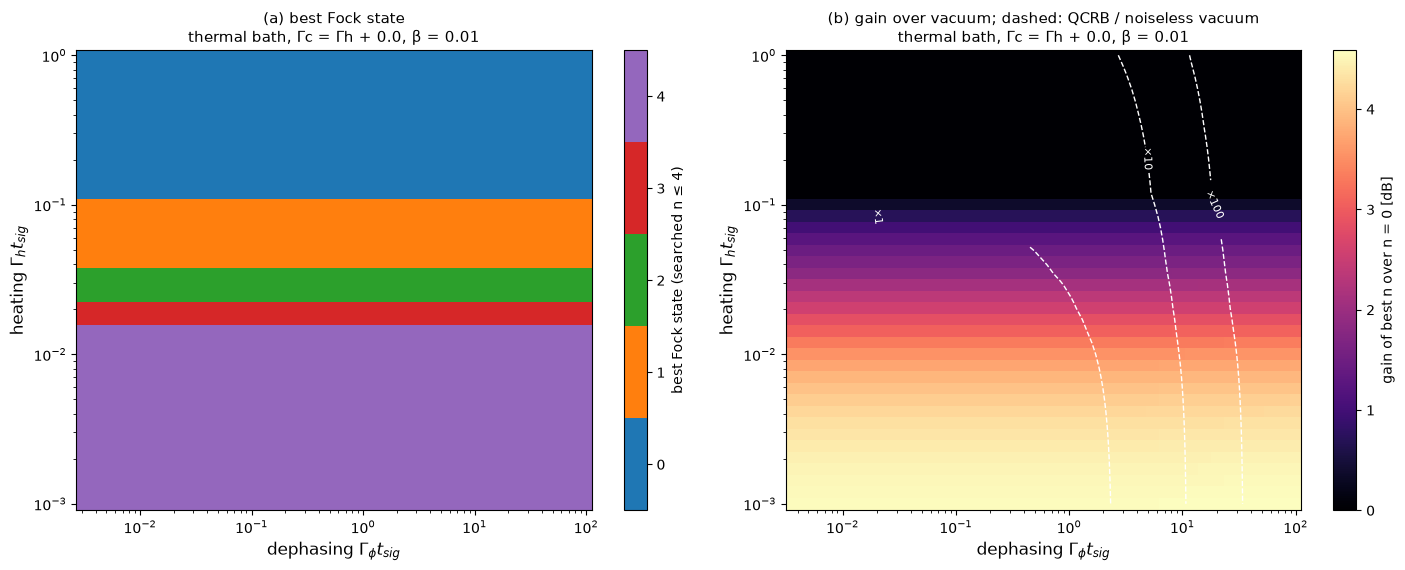

thermal bath, Γc = Γh + 0.0, β = 0.01: 40 × 40 points × 5 states in 301.1 s; 0 points dropped at the Fock cutoff
  n = 1 wins somewhere up to Γh·t = 0.100
  n = 2 wins somewhere up to Γh·t = 0.035
  n = 3 wins somewhere up to Γh·t = 0.020
  n = 4 wins somewhere up to Γh·t = 0.014
thermal bath, Γc = Γh + 0.0, β = 0.50: 40 × 40 points × 5 states in 200.7 s; 0 points dropped at the Fock cutoff
  n = 1 wins somewhere up to Γh·t = 0.242
  n = 2 wins somewhere up to Γh·t = 0.100
  n = 3 wins somewhere up to Γh·t = 0.059
  n = 4 wins somewhere up to Γh·t = 0.035
thermal bath, Γc = Γh + 0.0, β = 1.00: 40 × 40 points × 5 states in 195.5 s; 0 points dropped at the Fock cutoff
  n = 1 wins somewhere up to Γh·t = 0.242
  n = 2 wins somewhere up to Γh·t = 0.084
  n = 3 wins somewhere up to Γh·t = 0.035
  n = 4 wins somewhere up to Γh·t = 0.014
thermal bath, Γc = Γh + 0.0, β = 2.00: 40 × 40 points × 5 states in 189.1 s; 0 points dropped at the Fock cutoff
  n = 1 wins somewhere up to Γh·t = 0.170
  

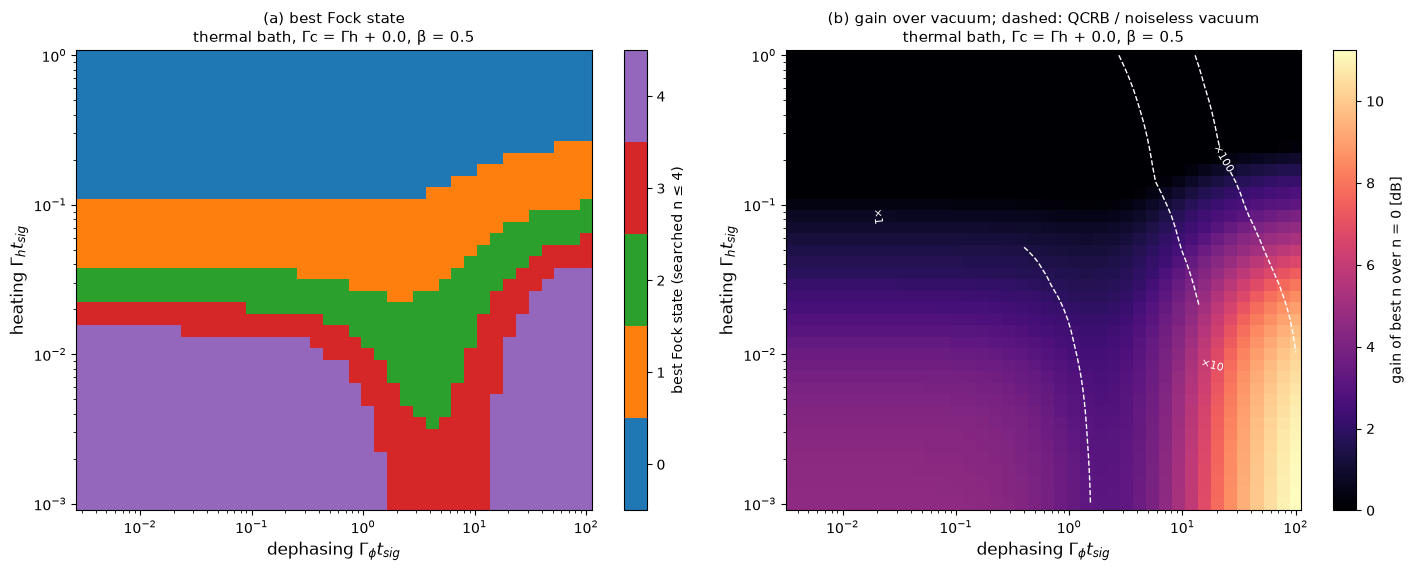

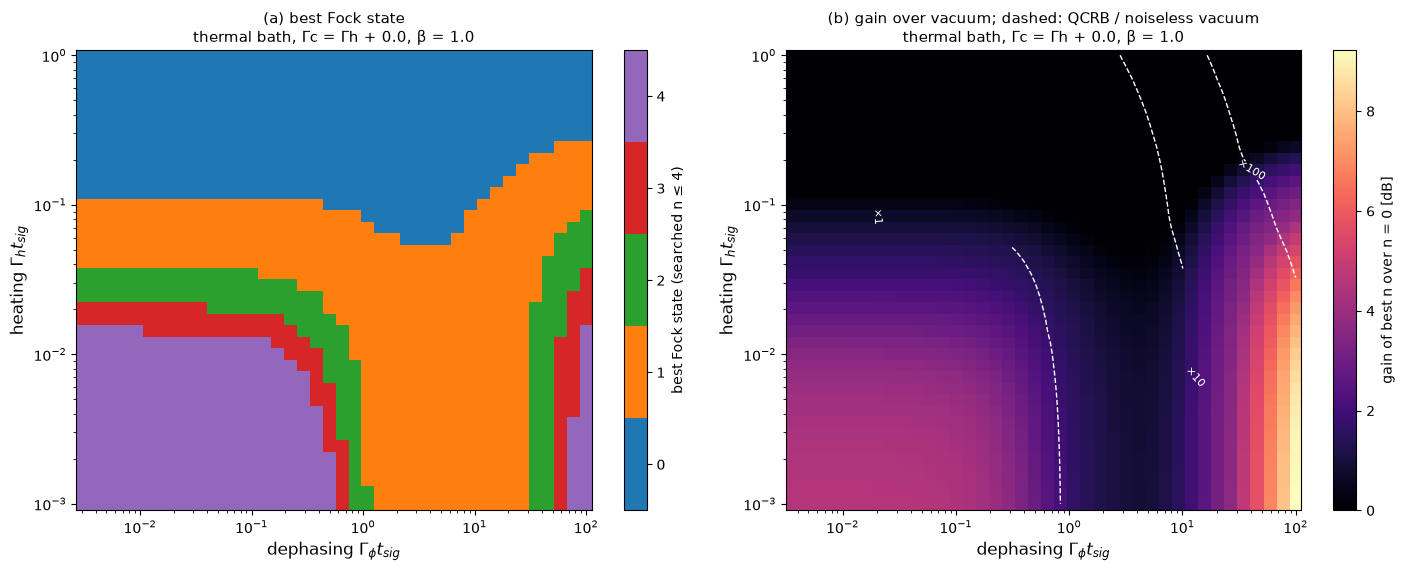

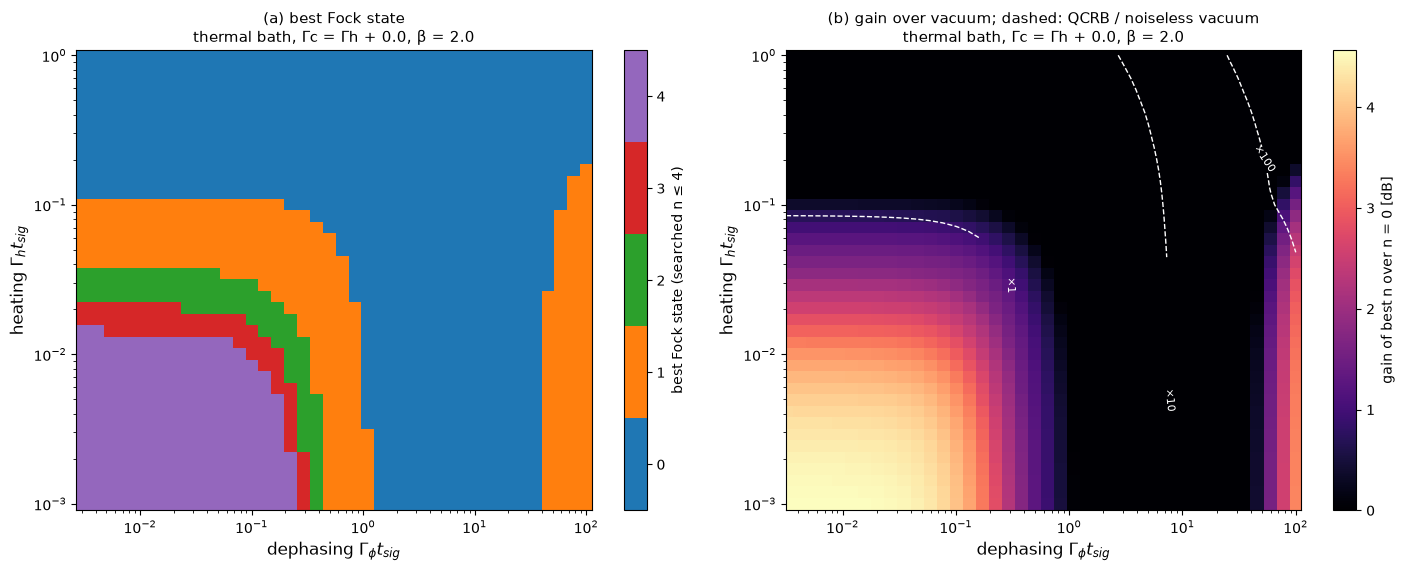

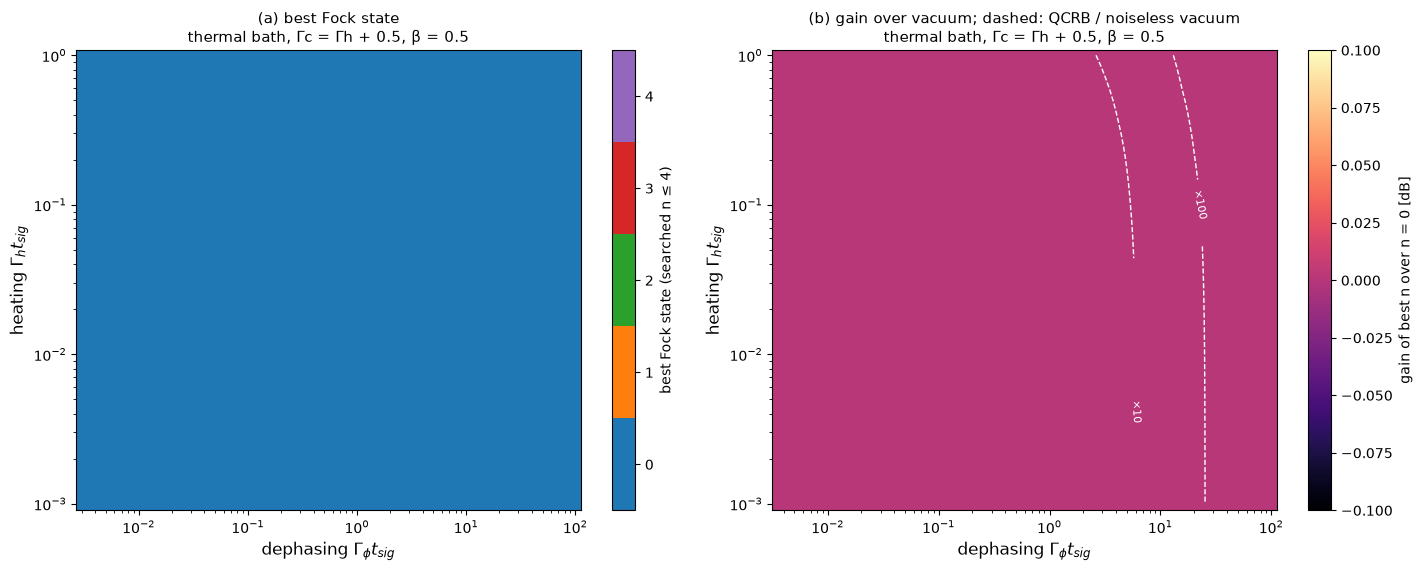

(gps = [0.0031622776601683794, 0.004124626382901352, 0.005379838403443687, 0.00701703828670383, 0.009152473108773892, 0.011937766417144363, 0.015570684047537309, 0.020309176209047358, 0.026489692876105284, 0.0345510729459222  …  9.15247310877389, 11.937766417144363, 15.57068404753731, 20.309176209047358, 26.489692876105284, 34.5510729459222, 45.06570337745473, 58.780160722749116, 76.66822074546215, 100.0], ghs = [0.001, 0.001193776641714437, 0.0014251026703029977, 0.0017012542798525892, 0.002030917620904735, 0.0024244620170823282, 0.0028942661247167516, 0.003455107294592218, 0.004124626382901352, 0.004923882631706742  …  0.20309176209047358, 0.24244620170823283, 0.2894266124716751, 0.3455107294592219, 0.4124626382901352, 0.4923882631706739, 0.5878016072274913, 0.7017038286703827, 0.8376776400682919, 1.0], Q = [0.8707423860581073 0.87100798615337 … 2.017183879630204 2.2397159507322932; 2.0810259398275255 2.081262114934143 … 3.1677856347654187 3.3854318829691126; … ; 2.168393435108233 2.

In [25]:
atlas_hot  = plot_heating_dephasing_atlas(Gc=0.0, thermal=true, β=0.01);
 
atlas_hot_mid  = plot_heating_dephasing_atlas(Gc=0.0, thermal=true, β=0.5);

atlas_hot_hi  = plot_heating_dephasing_atlas(Gc=0.0, thermal=true, β=1.0);

atlas_hot_extreme  = plot_heating_dephasing_atlas(Gc=0.0, thermal=true, β=2.0);

atlas_hot  = plot_heating_dephasing_atlas(Gc=0.5, thermal=true, β=0.5);
 
 
 
 